<a href="https://colab.research.google.com/github/Ved0705/VedSomeshLawand/blob/main/VedSomeshLawand.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display all columns
pd.set_option('display.max_columns', None)

In [2]:
# Load the dataset into a DataFrame

df = pd.read_csv("https://raw.githubusercontent.com/salemprakash/EDA/main/Data/KosteckiDillon.csv")

# Display the first five rows
df.head()

,rownames,id,time,dos,hatype,age,airq,medication,headache,sex
0,1,1,-11,753,Aura,30,9.0,continuing,yes,female
1,2,1,-10,754,Aura,30,7.0,continuing,yes,female
2,3,1,-9,755,Aura,30,10.0,continuing,yes,female
3,4,1,-8,756,Aura,30,13.0,continuing,yes,female
4,5,1,-7,757,Aura,30,18.0,continuing,yes,female


In [3]:
# Display the shape of the dataset

print("Shape of the dataset:", df.shape)

# Display column names

print("\nColumn Names:")
print(df.columns)

# Display dataset information

print("\nDataset Information:")
df.info()

Shape of the dataset: (4152, 10)

Column Names:
Index(['rownames', 'id', 'time', 'dos', 'hatype', 'age', 'airq', 'medication',
       'headache', 'sex'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4152 entries, 0 to 4151
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   rownames    4152 non-null   int64  
 1   id          4152 non-null   int64  
 2   time        4152 non-null   int64  
 3   dos         4152 non-null   int64  
 4   hatype      4152 non-null   object 
 5   age         4152 non-null   int64  
 6   airq        4152 non-null   float64
 7   medication  4152 non-null   object 
 8   headache    4152 non-null   object 
 9   sex         4152 non-null   object 
dtypes: float64(1), int64(5), object(4)
memory usage: 324.5+ KB


In [4]:
# Display statistical summary of numerical columns

df.describe()

,rownames,id,time,dos,age,airq
count,4152.000000,4152.000000,4152.000000,4152.000000,4152.000000,4152.000000
mean,2076.500000,66.386802,15.455684,646.705925,42.363921,24.826012
std,1198.723488,39.121812,21.737211,335.770123,11.201244,9.514274
min,1.000000,1.000000,-29.000000,98.000000,18.000000,3.000000
25%,1038.750000,33.000000,3.000000,384.000000,33.000000,18.000000
50%,2076.500000,67.000000,12.000000,623.000000,44.000000,24.000000
75%,3114.250000,100.000000,24.000000,950.000000,50.000000,29.000000
max,4152.000000,133.000000,99.000000,1239.000000,66.000000,73.000000


In [5]:
# Display summary of categorical columns

df.describe(include='object')

,hatype,medication,headache,sex
count,4152,4152,4152,4152
unique,3,3,2,2
top,No Aura,continuing,yes,female
freq,1985,2386,2666,3545


In [6]:
# Display the data type of each column

df.dtypes

,0
rownames,int64
id,int64
time,int64
dos,int64
hatype,object
age,int64
airq,float64
medication,object
headache,object
sex,object


In [7]:
# Check for missing values in each column

df.isnull().sum()

,0
rownames,0
id,0
time,0
dos,0
hatype,0
age,0
airq,0
medication,0
headache,0
sex,0


In [8]:
# Handle missing values

if df.isnull().sum().sum() == 0:
    print("The dataset does not contain any missing values.")
else:
    df = df.dropna()
    print("Missing values have been removed.")

The dataset does not contain any missing values.


In [9]:
# Check for duplicate rows

print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [10]:
# Remove duplicate rows if any exist

df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (4152, 10)


In [11]:
# Remove leading and trailing spaces from column names

df.columns = df.columns.str.strip()

# Display updated column names

print(df.columns)

Index(['rownames', 'id', 'time', 'dos', 'hatype', 'age', 'airq', 'medication',
       'headache', 'sex'],
      dtype='object')


In [12]:
# Convert categorical columns to category datatype

categorical_columns = ['hatype', 'medication', 'headache', 'sex']

for column in categorical_columns:
    df[column] = df[column].astype('category')

# Display updated data types

df.dtypes

,0
rownames,int64
id,int64
time,int64
dos,int64
hatype,category
age,int64
airq,float64
medication,category
headache,category
sex,category


In [13]:
# Display the first five rows after cleaning and transformation

df.head()

,rownames,id,time,dos,hatype,age,airq,medication,headache,sex
0,1,1,-11,753,Aura,30,9.0,continuing,yes,female
1,2,1,-10,754,Aura,30,7.0,continuing,yes,female
2,3,1,-9,755,Aura,30,10.0,continuing,yes,female
3,4,1,-8,756,Aura,30,13.0,continuing,yes,female
4,5,1,-7,757,Aura,30,18.0,continuing,yes,female


In [14]:
# Import visualization libraries

import matplotlib.pyplot as plt
import seaborn as sns

# Set plot style

sns.set_style("whitegrid")

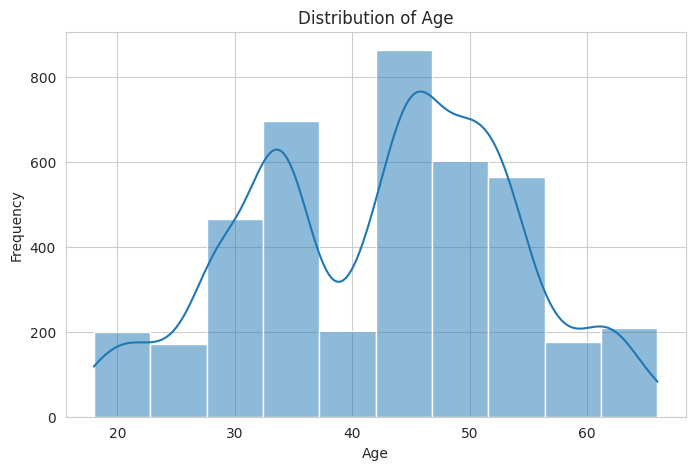

In [15]:
# Univariate Analysis - Distribution of Age

plt.figure(figsize=(8,5))
sns.histplot(df['age'], bins=10, kde=True)

plt.title("Distribution of Age")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

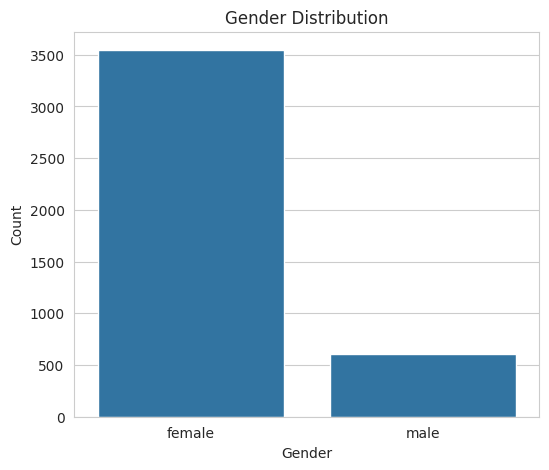

In [16]:
# Univariate Analysis - Distribution of Gender

plt.figure(figsize=(6,5))
sns.countplot(x='sex', data=df)

plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Count")

plt.show()

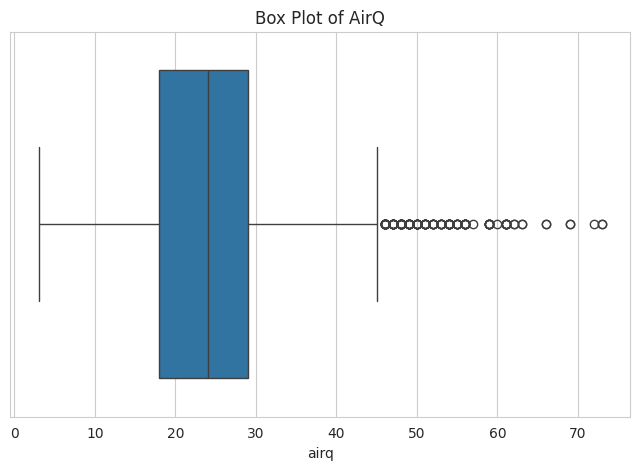

In [17]:
# Univariate Analysis - AirQ Distribution

plt.figure(figsize=(8,5))
sns.boxplot(x=df['airq'])

plt.title("Box Plot of AirQ")

plt.show()

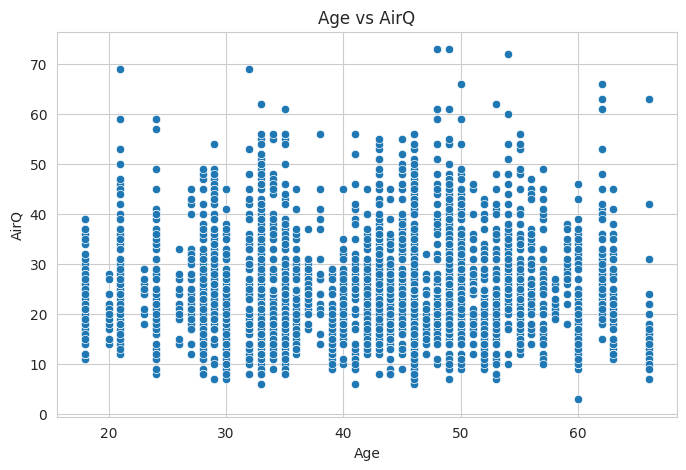

In [18]:
# Bivariate Analysis - Age vs AirQ

plt.figure(figsize=(8,5))
sns.scatterplot(x='age', y='airq', data=df)

plt.title("Age vs AirQ")
plt.xlabel("Age")
plt.ylabel("AirQ")

plt.show()

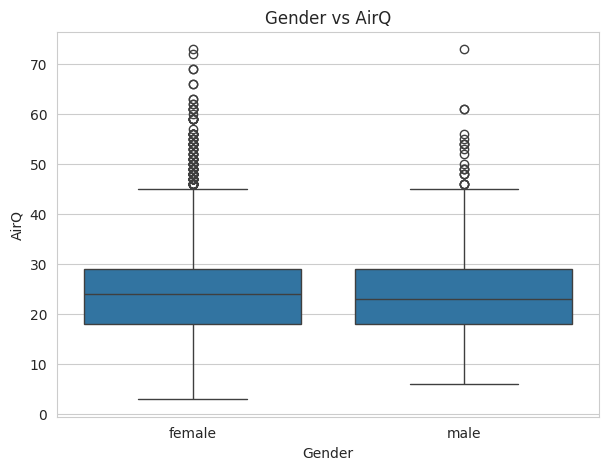

In [19]:
# Bivariate Analysis - Gender vs AirQ

plt.figure(figsize=(7,5))
sns.boxplot(x='sex', y='airq', data=df)

plt.title("Gender vs AirQ")
plt.xlabel("Gender")
plt.ylabel("AirQ")

plt.show()

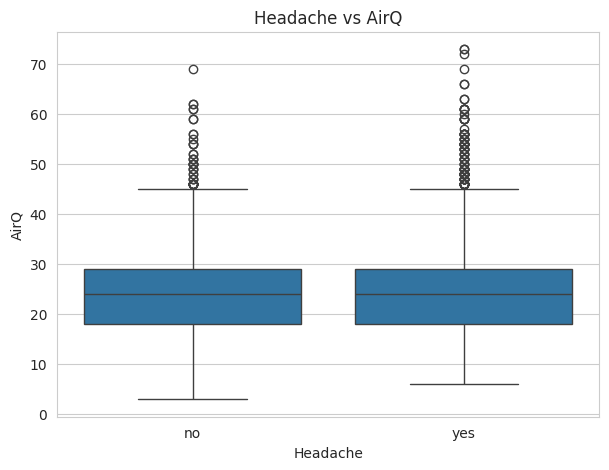

In [20]:
# Bivariate Analysis - Headache vs AirQ

plt.figure(figsize=(7,5))
sns.boxplot(x='headache', y='airq', data=df)

plt.title("Headache vs AirQ")
plt.xlabel("Headache")
plt.ylabel("AirQ")

plt.show()

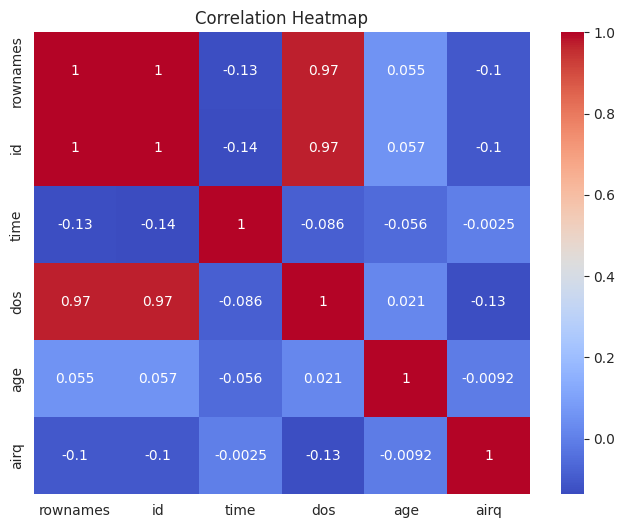

In [21]:
# Multivariate Analysis - Correlation Heatmap

plt.figure(figsize=(8,6))

numeric_df = df.select_dtypes(include=['number'])

sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm')

plt.title("Correlation Heatmap")

plt.show()

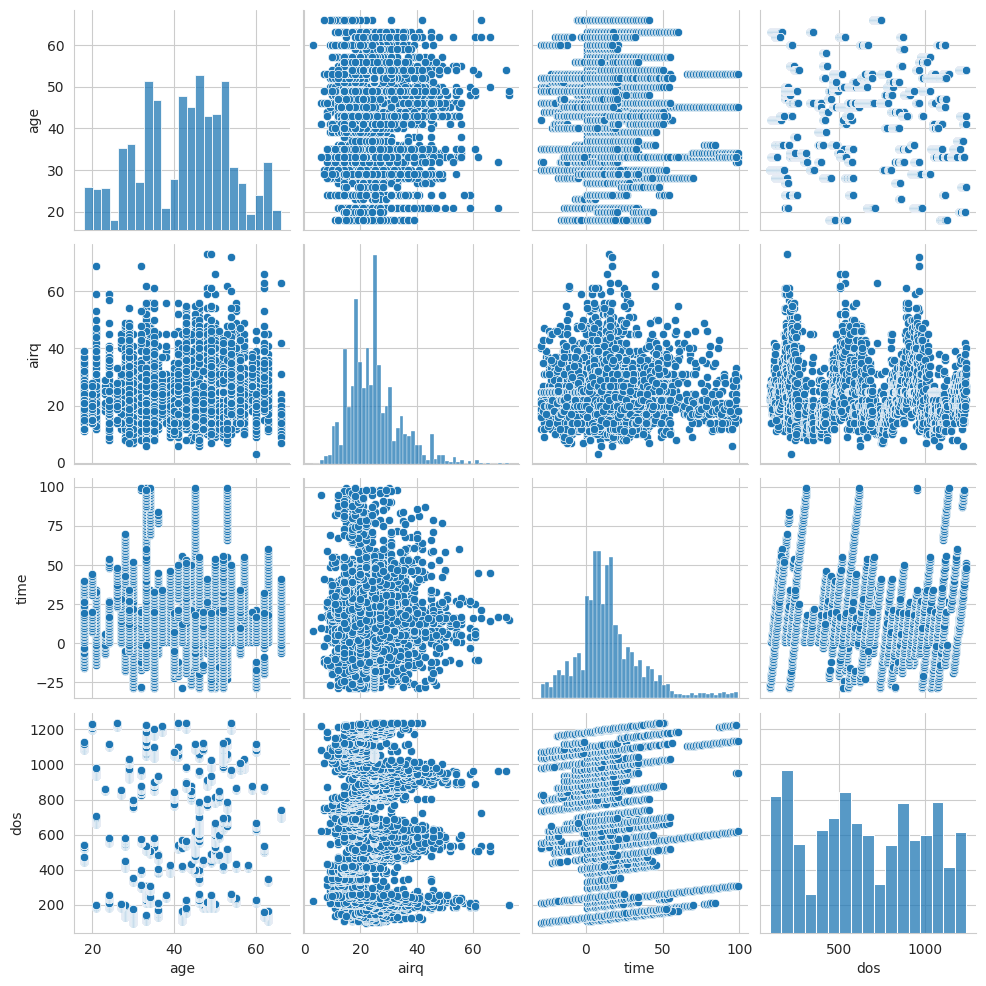

In [22]:
# Multivariate Analysis - Pair Plot

sns.pairplot(df[['age', 'airq', 'time', 'dos']], diag_kind='hist')

plt.show()

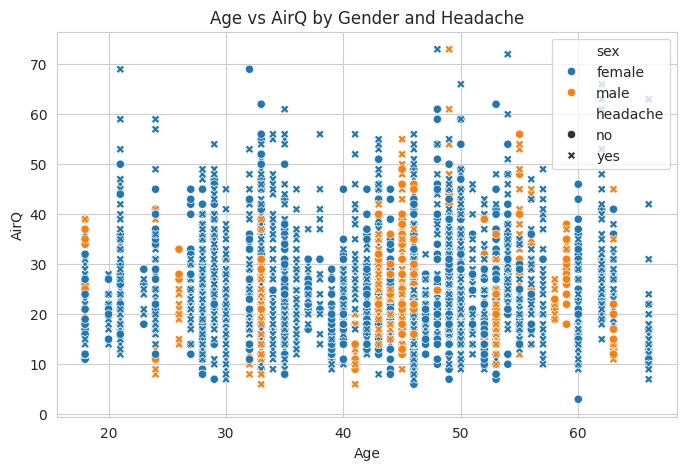

In [23]:
# Multivariate Analysis - Age vs AirQ grouped by Gender

plt.figure(figsize=(8,5))

sns.scatterplot(
    x='age',
    y='airq',
    hue='sex',
    style='headache',
    data=df
)

plt.title("Age vs AirQ by Gender and Headache")
plt.xlabel("Age")
plt.ylabel("AirQ")

plt.show()

In [24]:
# Conclusion

print("EDA Phase 1 Completed Successfully.")

print("\nKey Observations:")
print("1. The dataset contains no missing values.")
print("2. Duplicate rows were checked and removed if present.")
print("3. Categorical columns were transformed into category data type.")
print("4. Univariate, bivariate, and multivariate analyses were performed.")
print("5. Various visualizations helped understand the distribution and relationships among variables.")

EDA Phase 1 Completed Successfully.

Key Observations:
1. The dataset contains no missing values.
2. Duplicate rows were checked and removed if present.
3. Categorical columns were transformed into category data type.
4. Univariate, bivariate, and multivariate analyses were performed.
5. Various visualizations helped understand the distribution and relationships among variables.


In [25]:
#PHASE 2

In [26]:
# 1D Statistical Analysis

numeric_columns = df.select_dtypes(include=np.number).columns

print("Numerical Columns:")
print(list(numeric_columns))

print("\n--- Mean ---")
print(df[numeric_columns].mean())

print("\n--- Median ---")
print(df[numeric_columns].median())

print("\n--- Mode ---")
print(df[numeric_columns].mode().iloc[0])

print("\n--- Variance ---")
print(df[numeric_columns].var())

print("\n--- Standard Deviation ---")
print(df[numeric_columns].std())

print("\n--- Minimum ---")
print(df[numeric_columns].min())

print("\n--- Maximum ---")
print(df[numeric_columns].max())

print("\n--- Range ---")
print(df[numeric_columns].max() - df[numeric_columns].min())

print("\n--- Skewness ---")
print(df[numeric_columns].skew())

print("\n--- Kurtosis ---")
print(df[numeric_columns].kurtosis())

Numerical Columns:
['rownames', 'id', 'time', 'dos', 'age', 'airq']

--- Mean ---
rownames    2076.500000
id            66.386802
time          15.455684
dos          646.705925
age           42.363921
airq          24.826012
dtype: float64

--- Median ---
rownames    2076.5
id            67.0
time          12.0
dos          623.0
age           44.0
airq          24.0
dtype: float64

--- Mode ---
rownames      1.0
id           55.0
time          5.0
dos         213.0
age          46.0
airq         24.8
Name: 0, dtype: float64

--- Variance ---
rownames    1.436938e+06
id          1.530516e+03
time        4.725063e+02
dos         1.127416e+05
age         1.254679e+02
airq        9.052141e+01
dtype: float64

--- Standard Deviation ---
rownames    1198.723488
id            39.121812
time          21.737211
dos          335.770123
age           11.201244
airq           9.514274
dtype: float64

--- Minimum ---
rownames     1.0
id           1.0
time       -29.0
dos         98.0
age         1

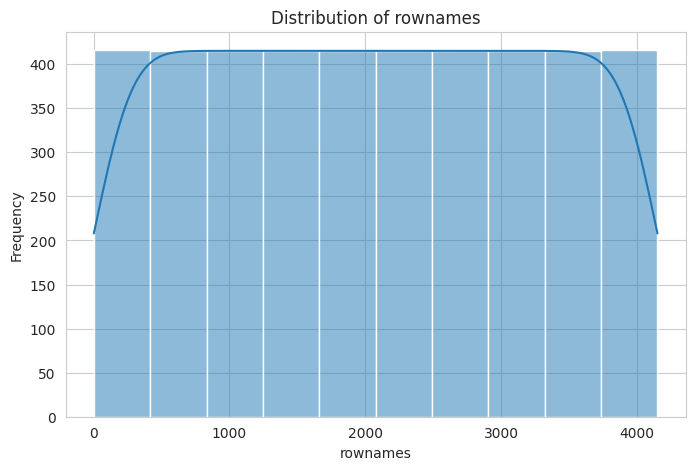

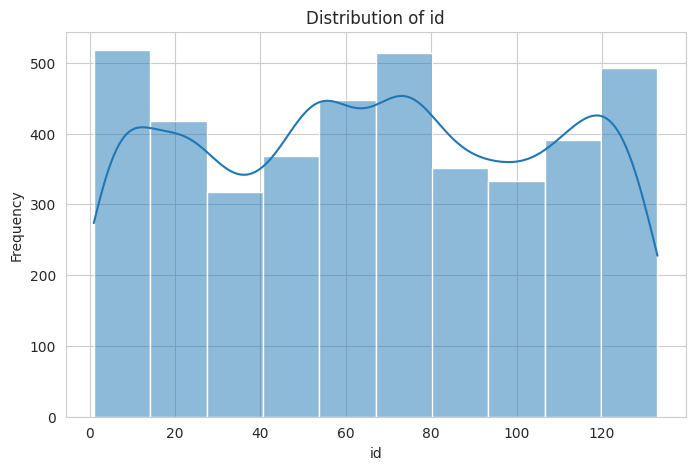

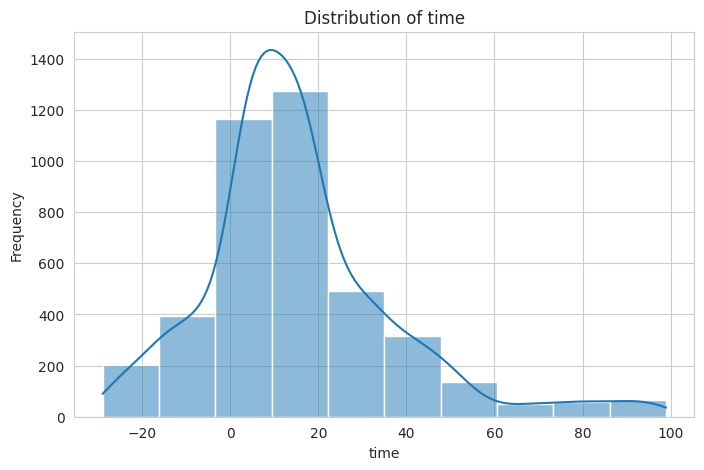

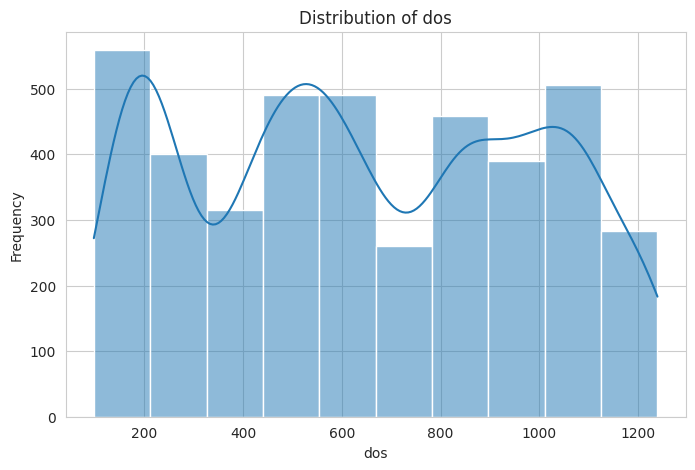

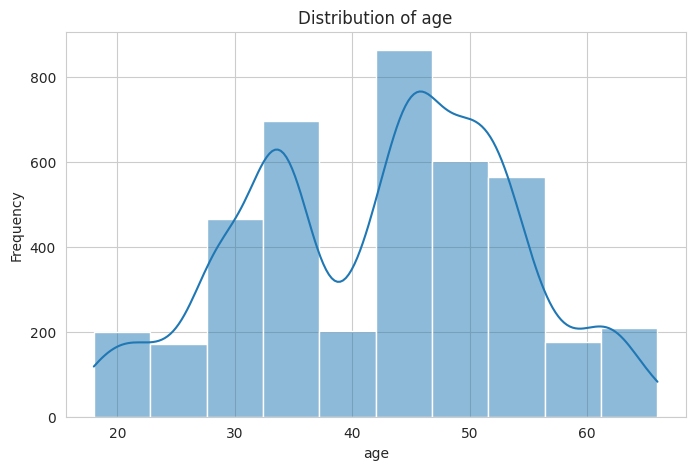

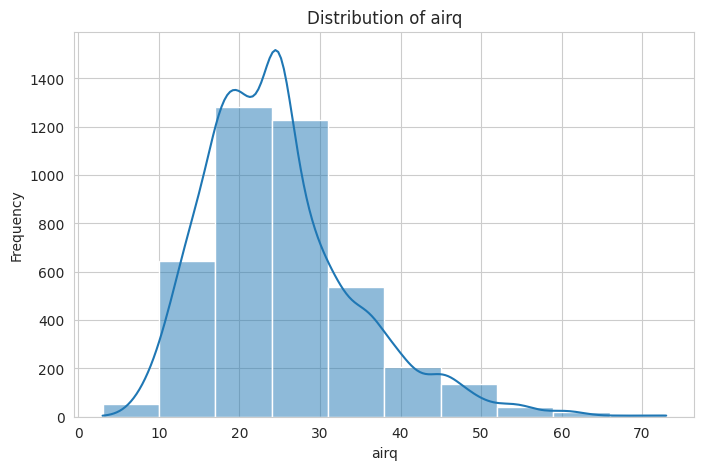

In [27]:
# 1D Statistical Analysis - Histograms

for column in numeric_columns:
    plt.figure(figsize=(8, 5))

    sns.histplot(df[column], bins=10, kde=True)

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")

    plt.show()

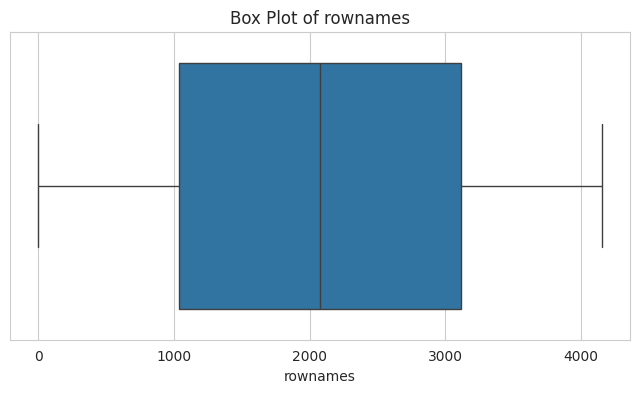

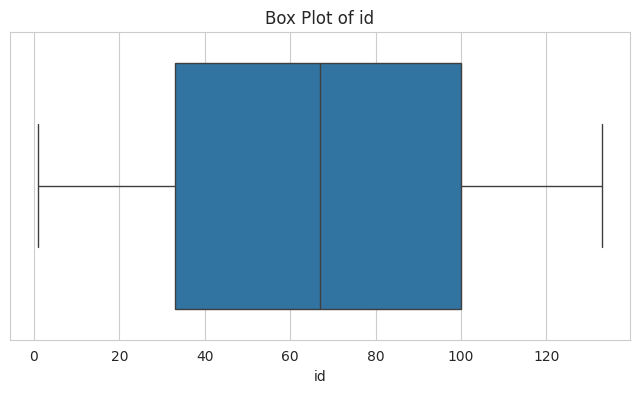

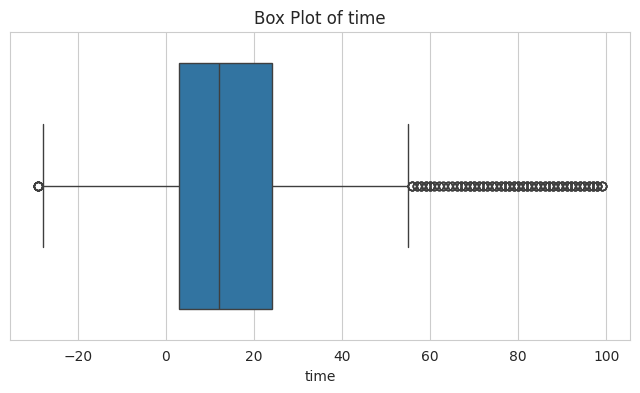

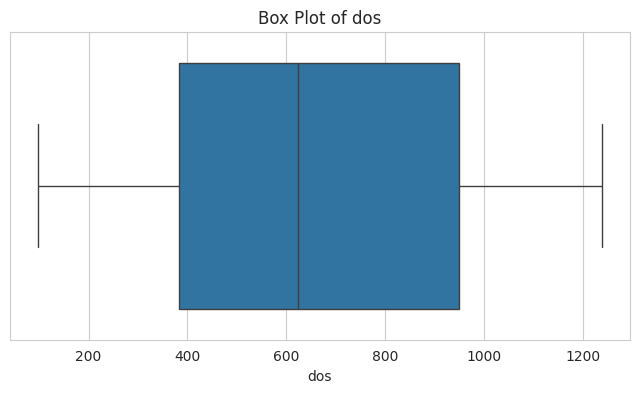

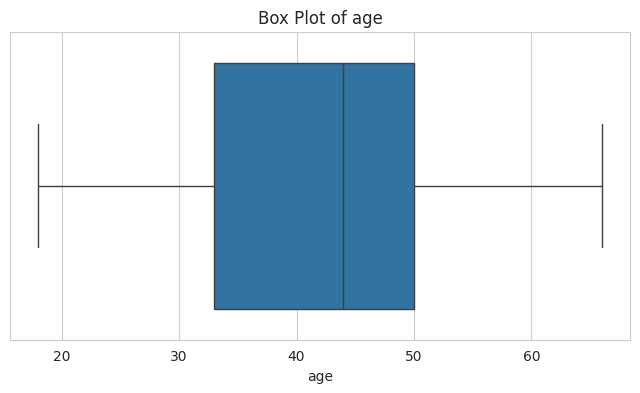

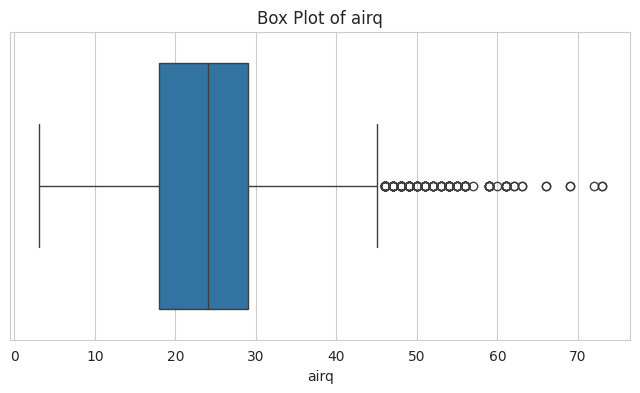

In [28]:
# 1D Statistical Analysis - Boxplots

for column in numeric_columns:
    plt.figure(figsize=(8, 4))

    sns.boxplot(x=df[column])

    plt.title(f"Box Plot of {column}")
    plt.xlabel(column)

    plt.show()


Frequency Table for hatype
hatype
No Aura    1985
Aura       1710
Mixed       457
Name: count, dtype: int64


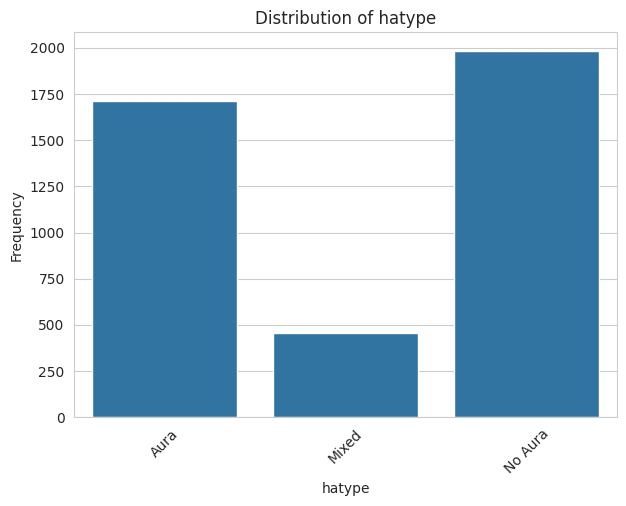


Frequency Table for medication
medication
continuing    2386
reduced        981
none           785
Name: count, dtype: int64


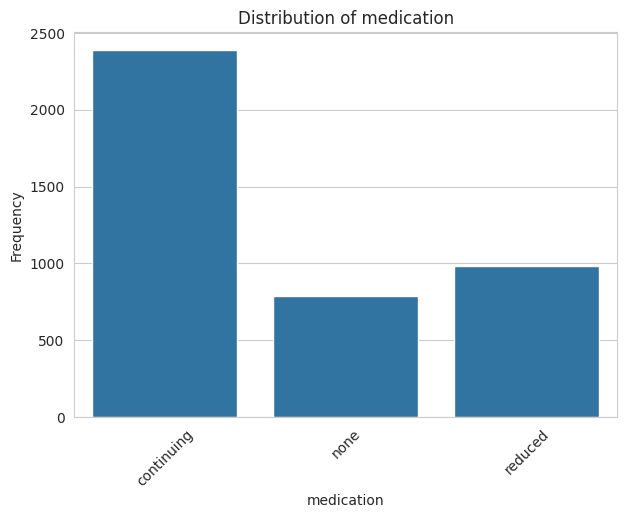


Frequency Table for headache
headache
yes    2666
no     1486
Name: count, dtype: int64


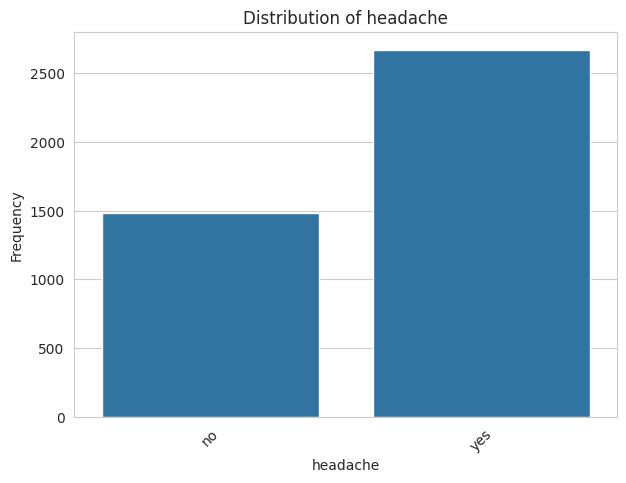


Frequency Table for sex
sex
female    3545
male       607
Name: count, dtype: int64


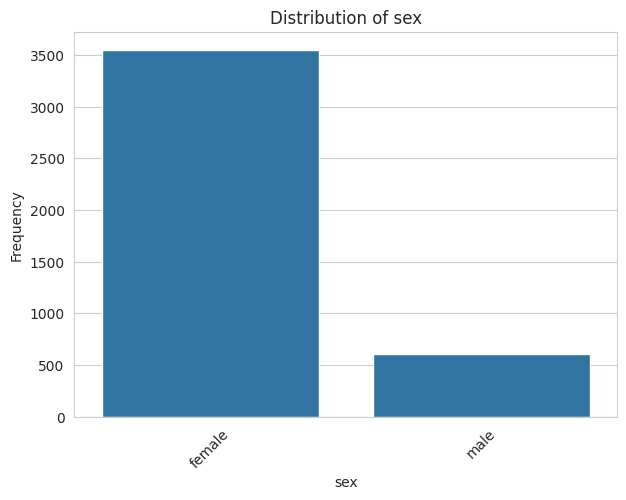

In [29]:
# 1D Statistical Analysis - Categorical Variables

categorical_columns = df.select_dtypes(
    include=['object', 'category']
).columns

for column in categorical_columns:

    print(f"\nFrequency Table for {column}")
    print(df[column].value_counts())

    plt.figure(figsize=(7, 5))

    sns.countplot(x=column, data=df)

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.xticks(rotation=45)

    plt.show()

In [30]:
# 2D Statistical Analysis - Covariance

print("Covariance Matrix:")

display(
    df[numeric_columns].cov()
)

Covariance Matrix:


,rownames,id,time,dos,age,airq
rownames,1.436938e+06,46868.254156,-3415.653337,391020.563599,735.430378,-1181.128499
id,4.686825e+04,1530.516212,-116.572351,12758.134976,25.041567,-38.041237
time,-3.415653e+03,-116.572351,472.506347,-627.521708,-13.581676,-0.522962
dos,3.910206e+05,12758.134976,-627.521708,112741.575508,79.537545,-415.088952
age,7.354304e+02,25.041567,-13.581676,79.537545,125.467867,-0.976561
airq,-1.181128e+03,-38.041237,-0.522962,-415.088952,-0.976561,90.521414


In [31]:
# 2D Statistical Analysis - Correlation

print("Correlation Matrix:")

display(
    df[numeric_columns].corr()
)

Correlation Matrix:


,rownames,id,time,dos,age,airq
rownames,1.000000,0.999403,-0.131084,0.971490,0.054772,-0.103562
id,0.999403,1.000000,-0.137080,0.971239,0.057145,-0.102202
time,-0.131084,-0.137080,1.000000,-0.085977,-0.055781,-0.002529
dos,0.971490,0.971239,-0.085977,1.000000,0.021148,-0.129934
age,0.054772,0.057145,-0.055781,0.021148,1.000000,-0.009163
airq,-0.103562,-0.102202,-0.002529,-0.129934,-0.009163,1.000000


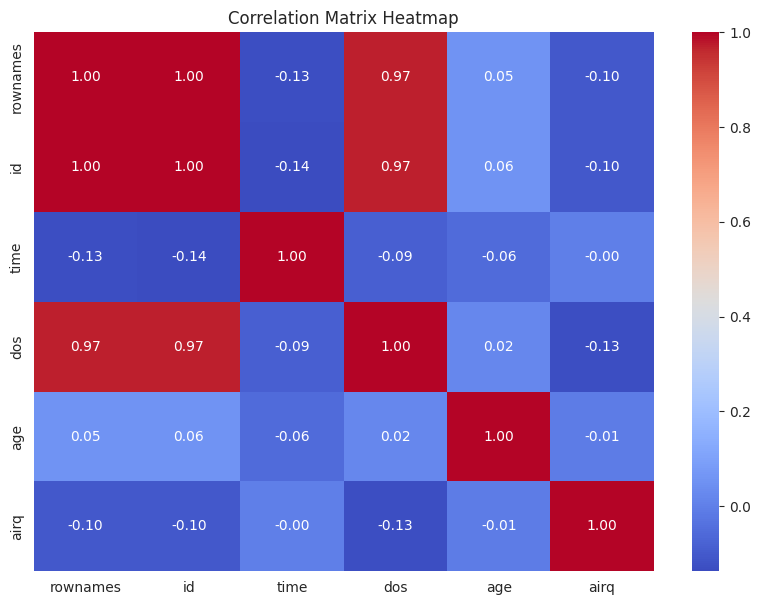

In [32]:
# 2D Statistical Analysis - Correlation Heatmap

plt.figure(figsize=(10, 7))

sns.heatmap(
    df[numeric_columns].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Matrix Heatmap")

plt.show()

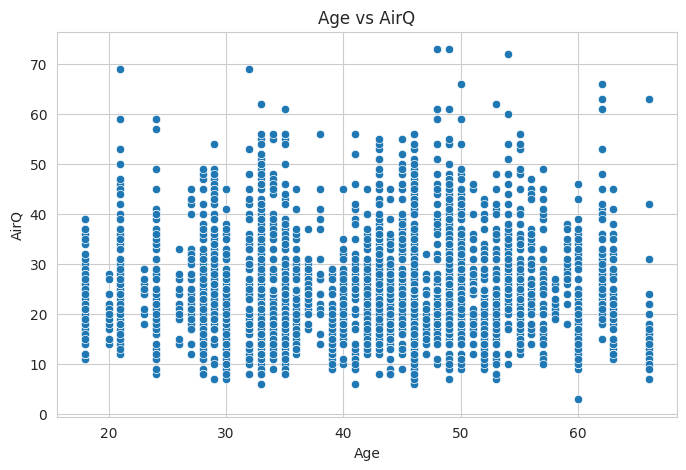

In [33]:
# 2D Statistical Analysis - Numerical vs Numerical

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x='age',
    y='airq',
    data=df
)

plt.title("Age vs AirQ")
plt.xlabel("Age")
plt.ylabel("AirQ")

plt.show()

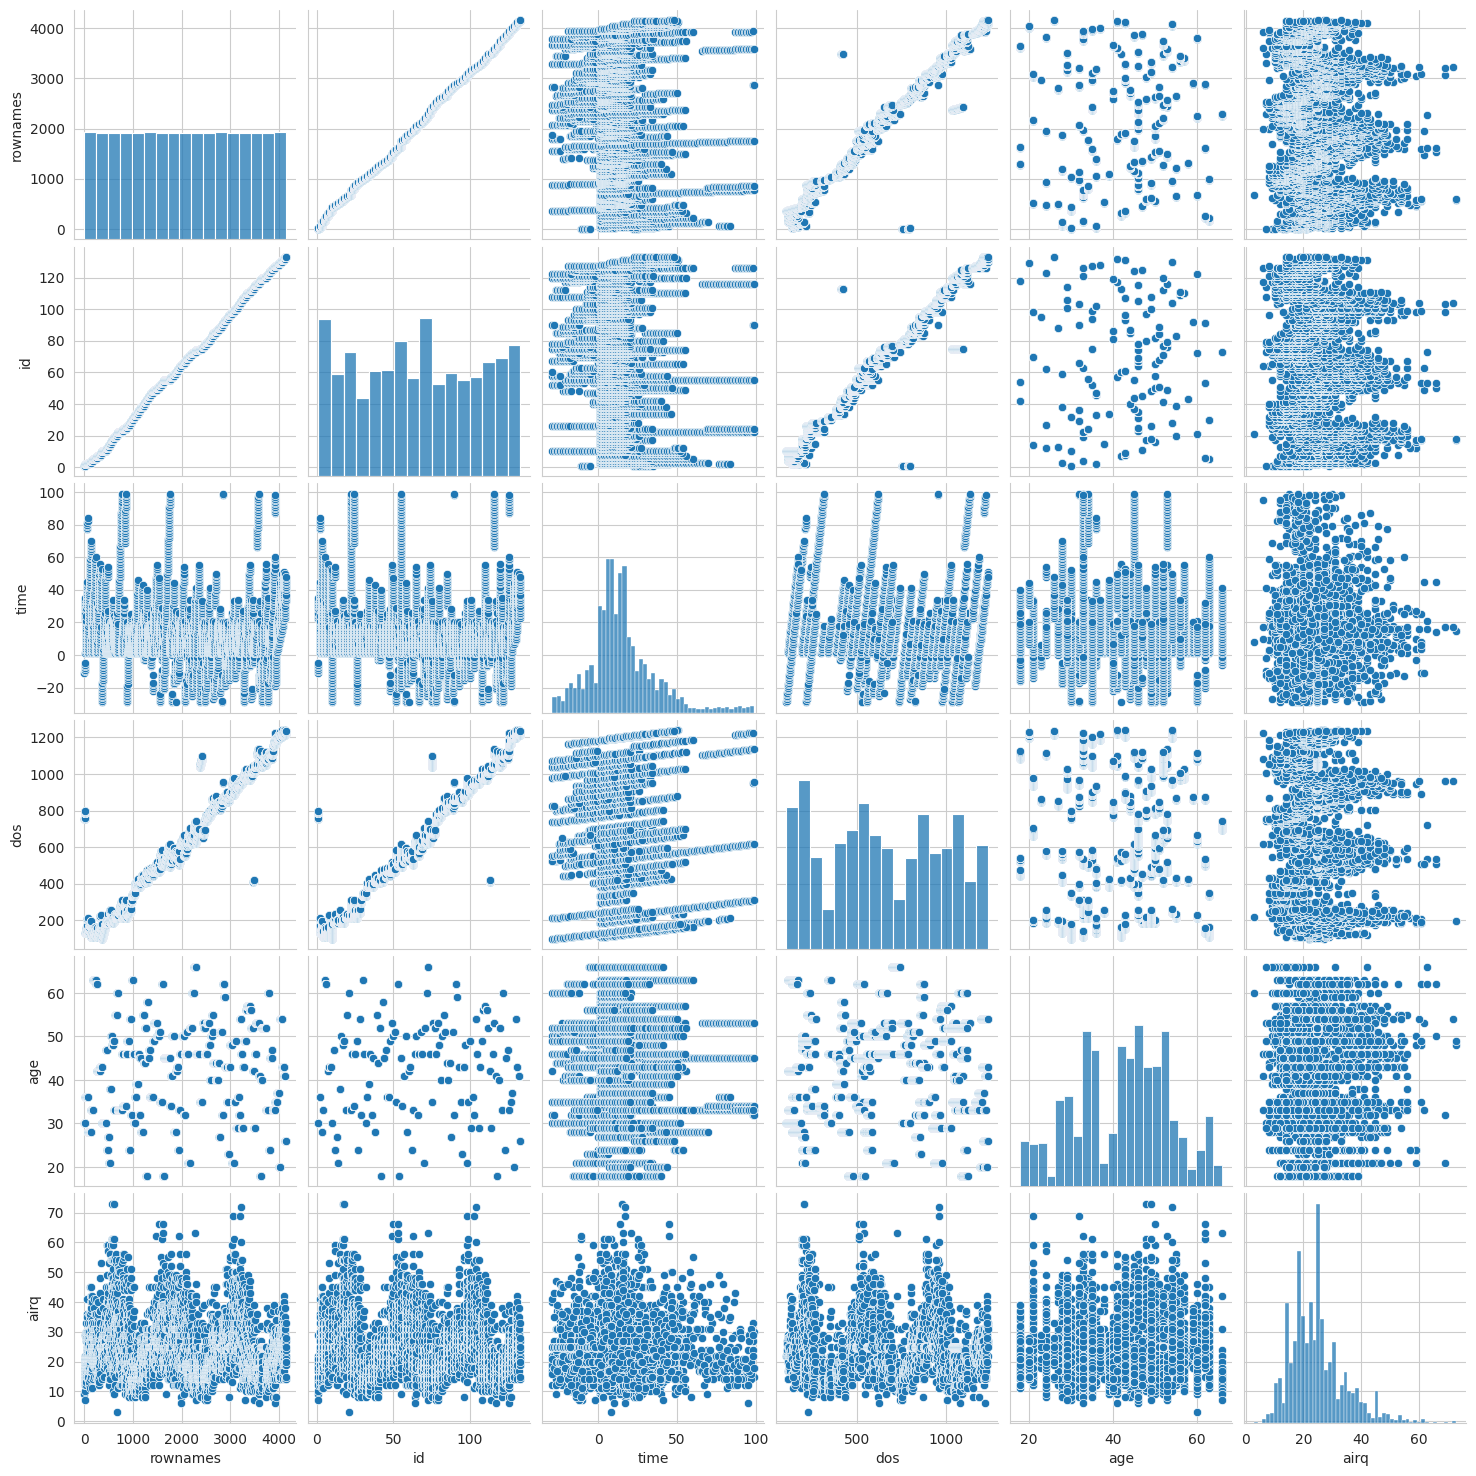

In [34]:
# 2D Statistical Analysis - Pairwise Relationships

sns.pairplot(
    df[numeric_columns],
    diag_kind='hist'
)

plt.show()

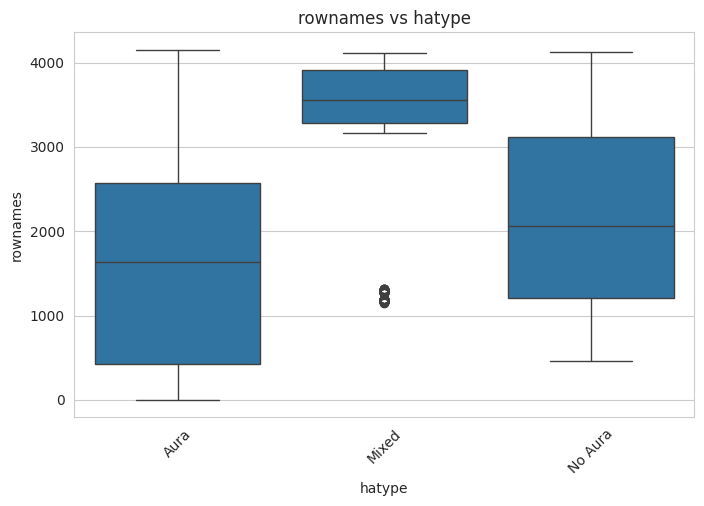

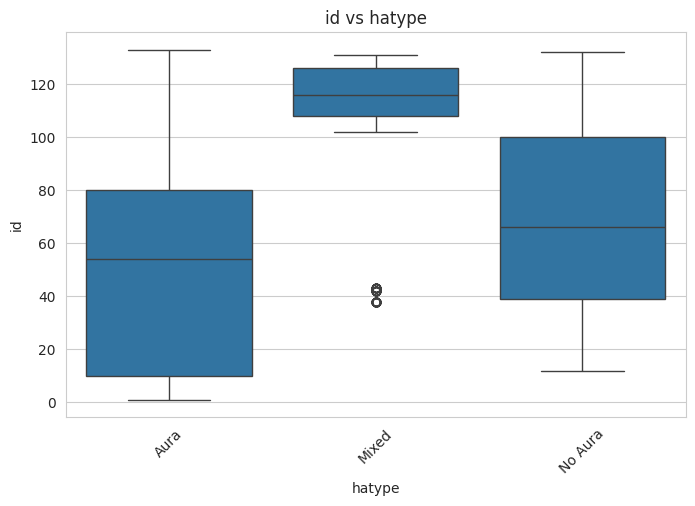

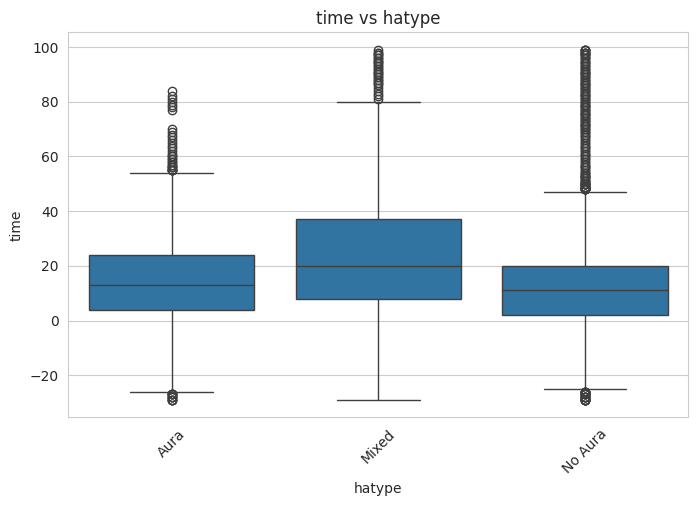

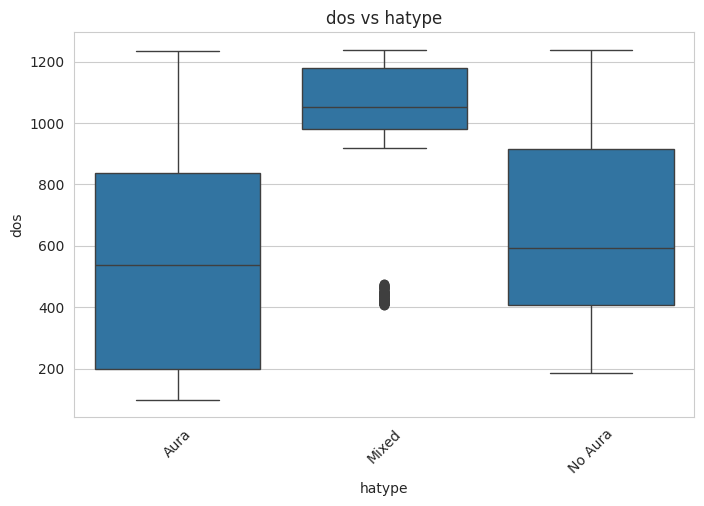

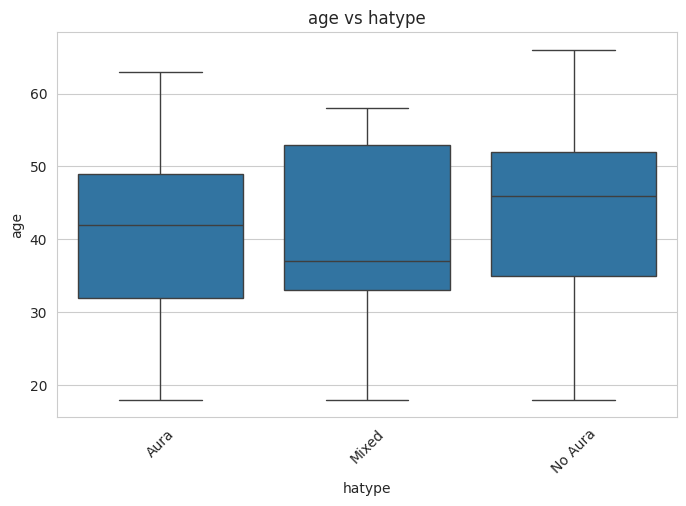

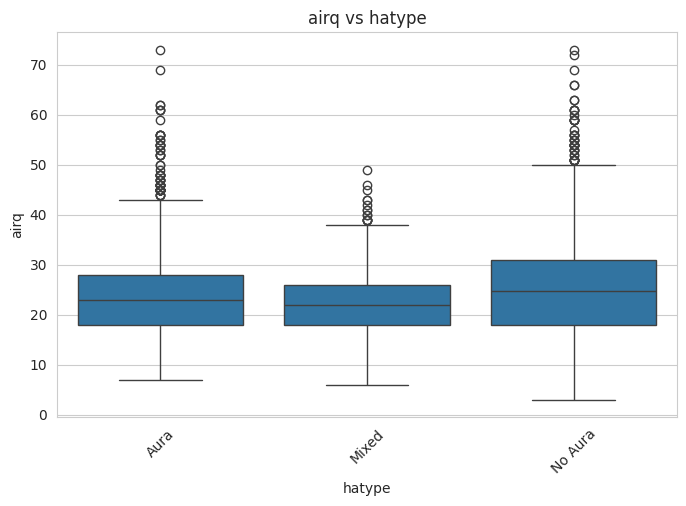

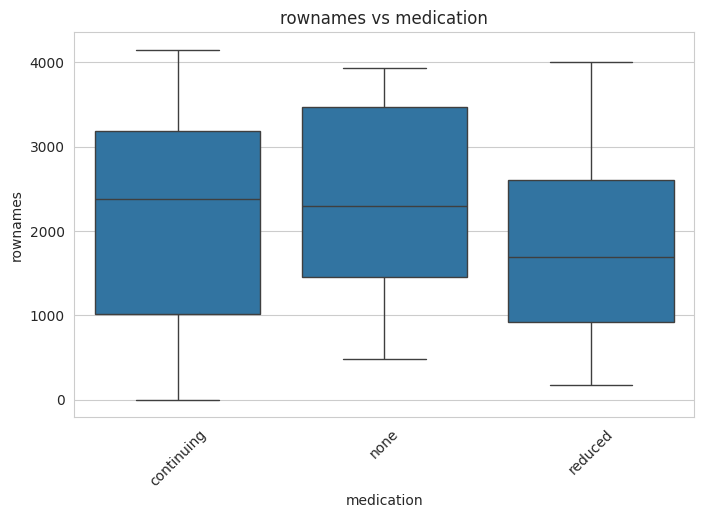

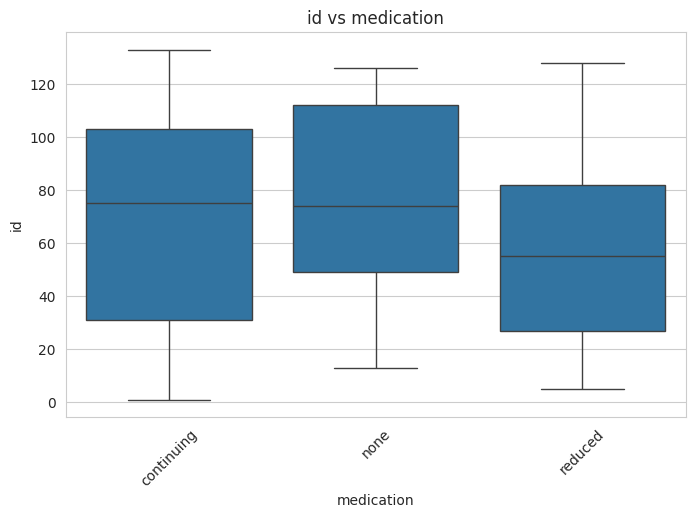

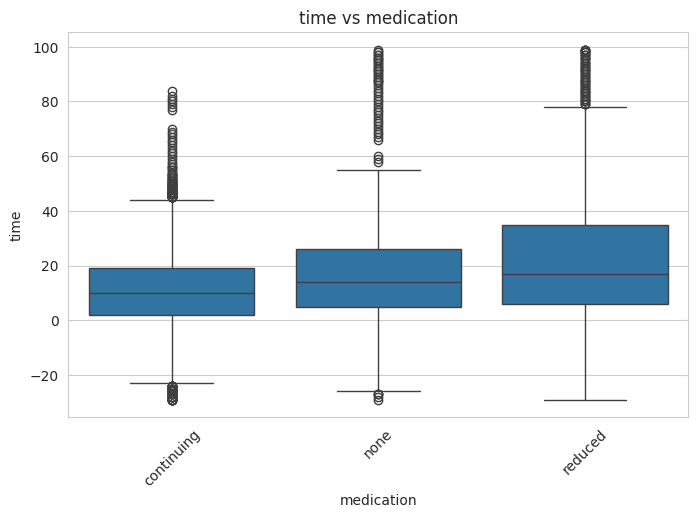

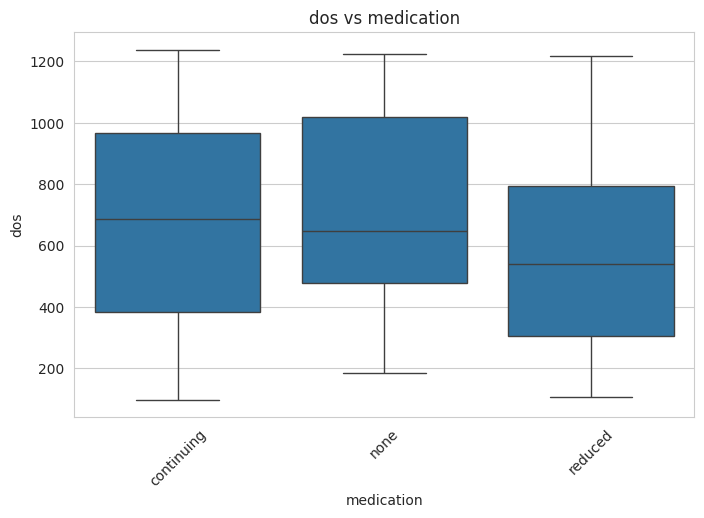

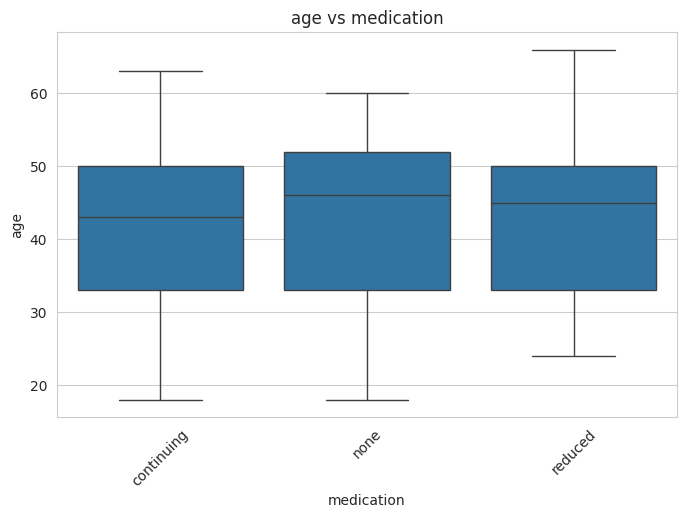

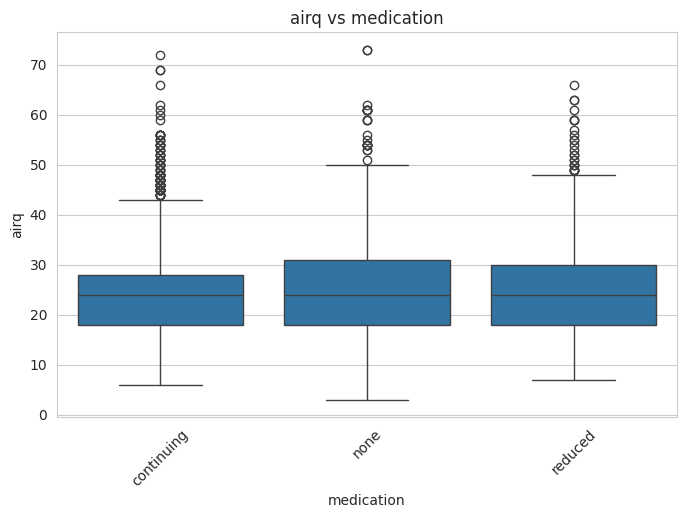

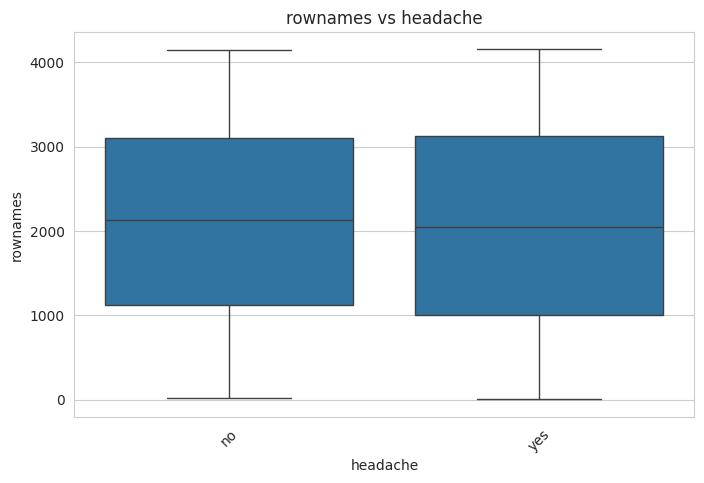

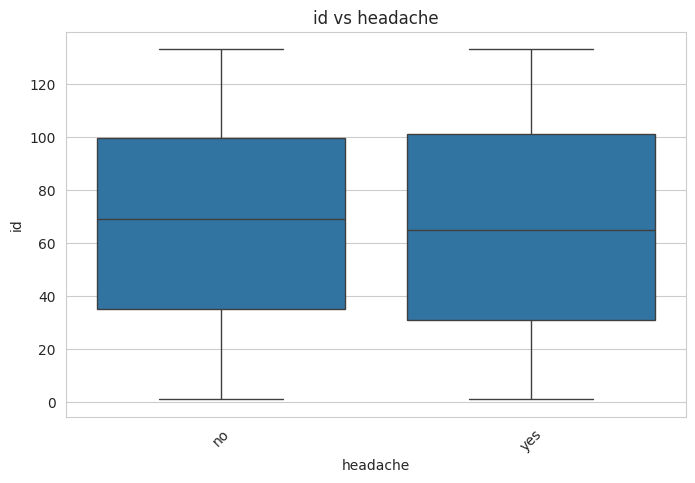

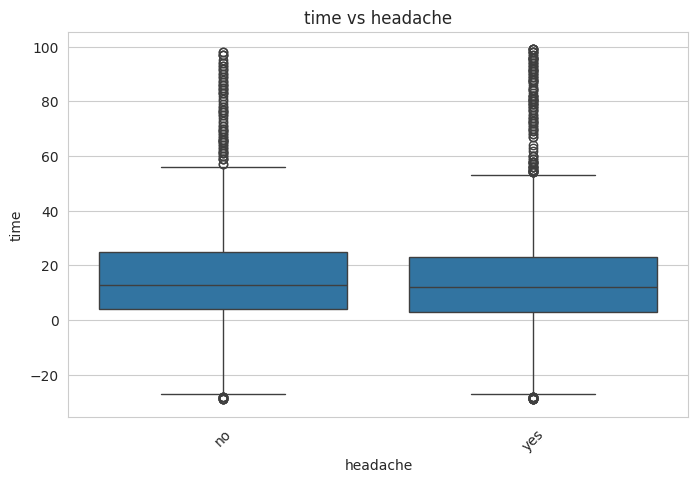

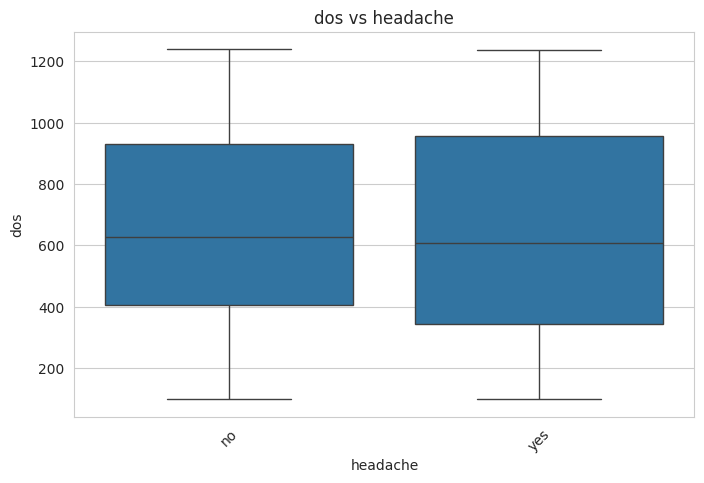

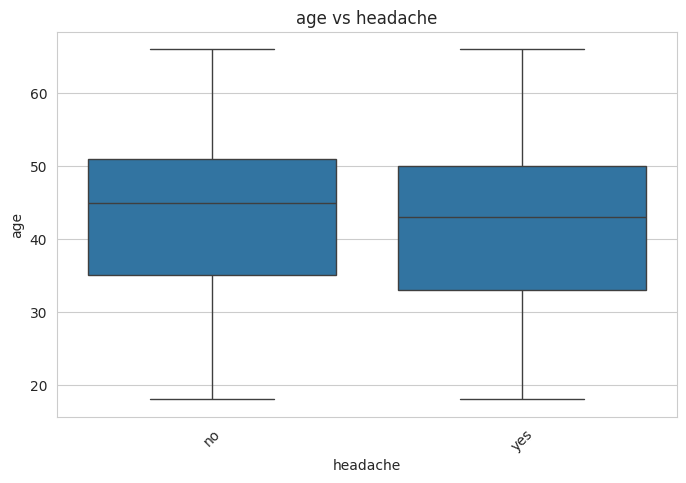

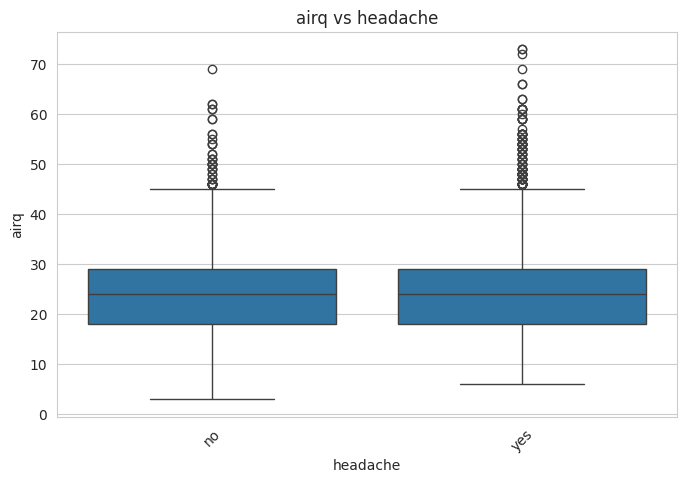

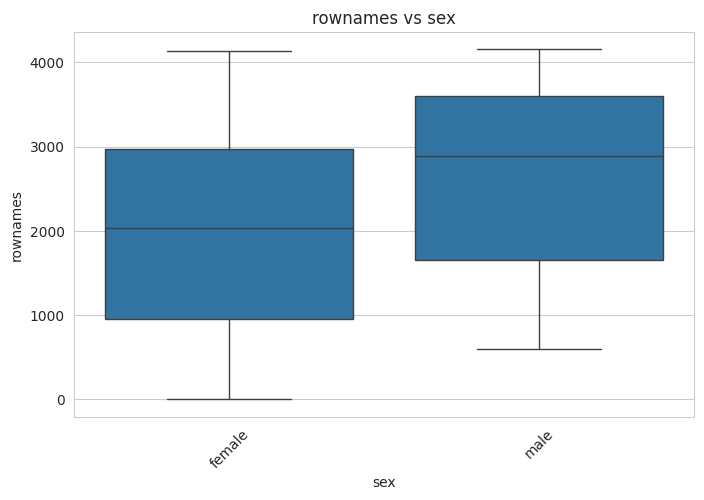

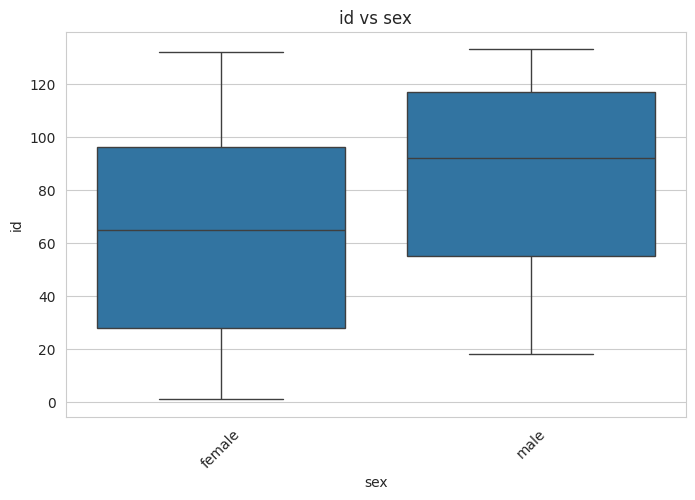

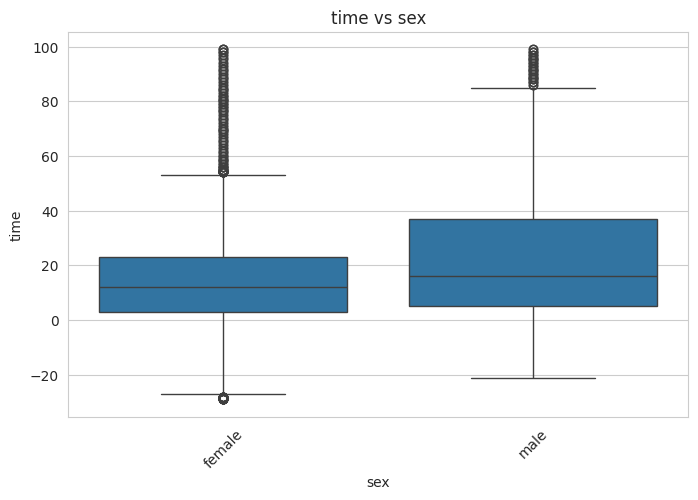

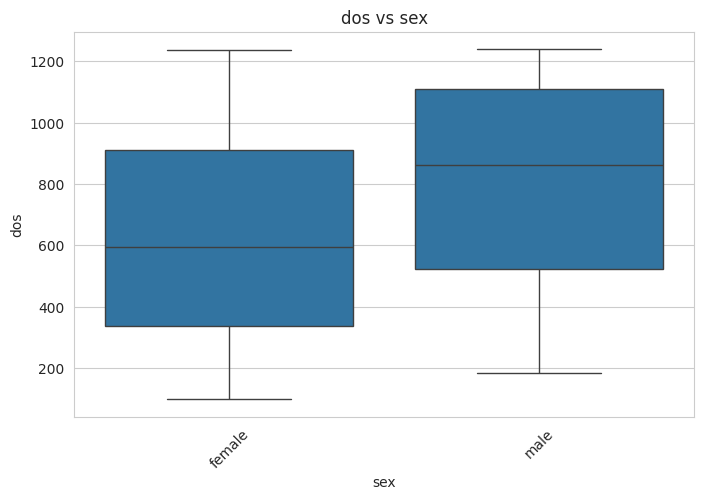

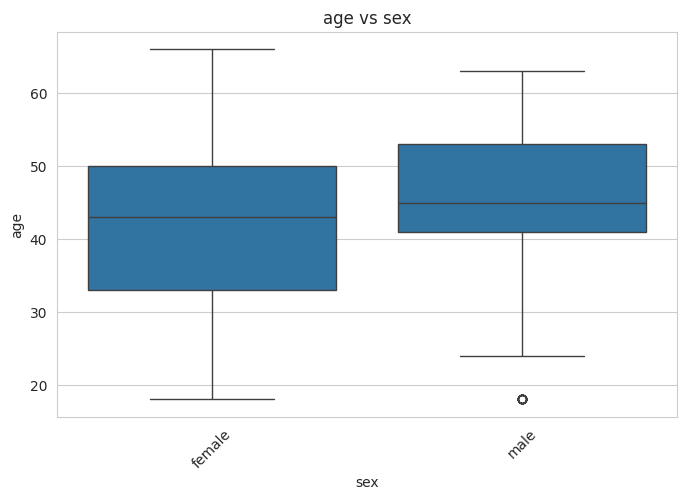

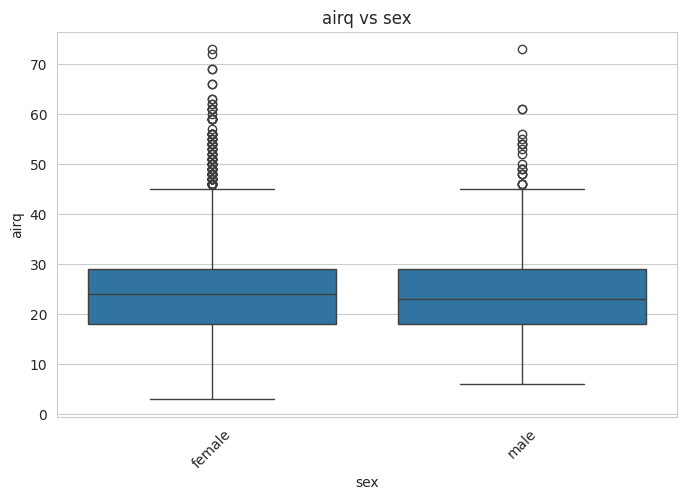

In [35]:
# 2D Statistical Analysis - Categorical vs Numerical

for cat_col in categorical_columns:

    for num_col in numeric_columns:

        plt.figure(figsize=(8, 5))

        sns.boxplot(
            x=cat_col,
            y=num_col,
            data=df
        )

        plt.title(f"{num_col} vs {cat_col}")
        plt.xlabel(cat_col)
        plt.ylabel(num_col)
        plt.xticks(rotation=45)

        plt.show()


Contingency Table: hatype vs medication


medication,continuing,none,reduced
hatype,,,
Aura,1079,354,277
Mixed,194,113,150
No Aura,1113,318,554


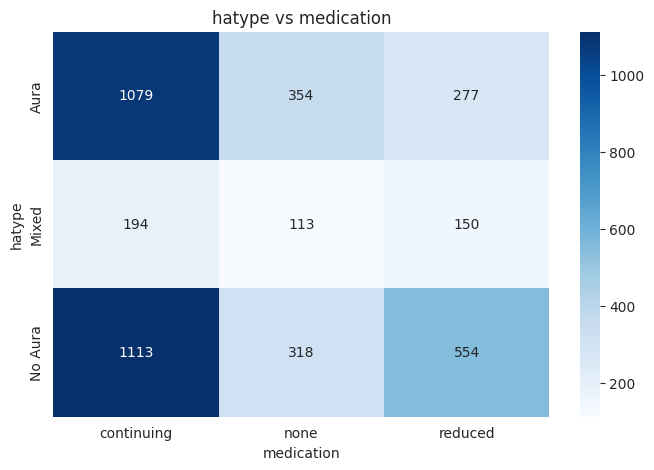


Contingency Table: hatype vs headache


headache,no,yes
hatype,,
Aura,581,1129
Mixed,96,361
No Aura,809,1176


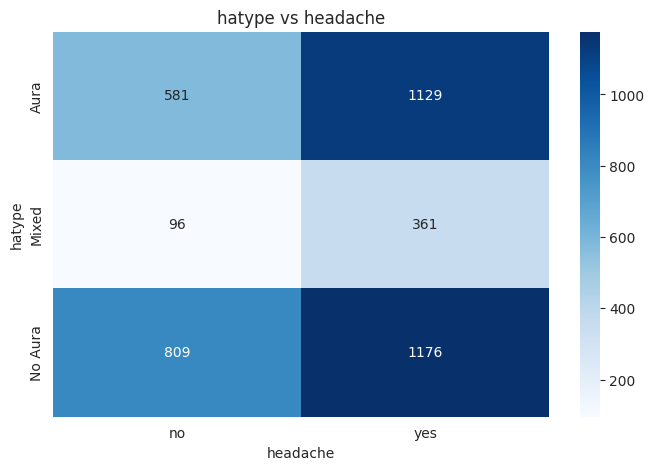


Contingency Table: hatype vs sex


sex,female,male
hatype,,
Aura,1593,117
Mixed,291,166
No Aura,1661,324


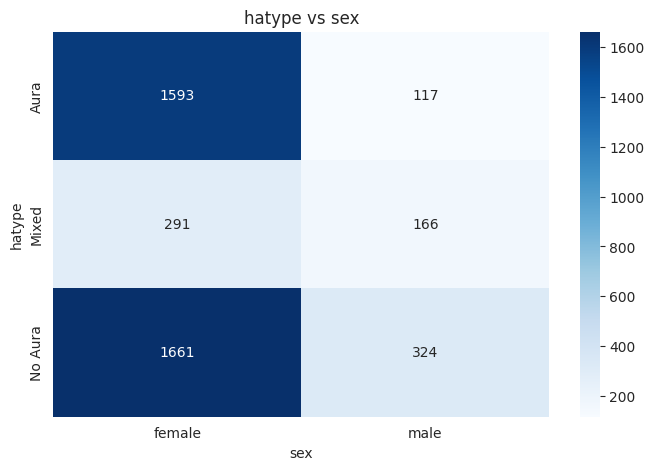


Contingency Table: medication vs headache


headache,no,yes
medication,,
continuing,825,1561
none,440,345
reduced,221,760


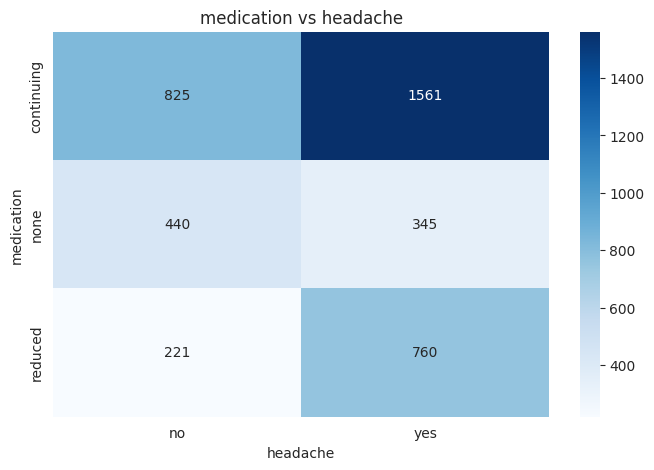


Contingency Table: medication vs sex


sex,female,male
medication,,
continuing,2156,230
none,592,193
reduced,797,184


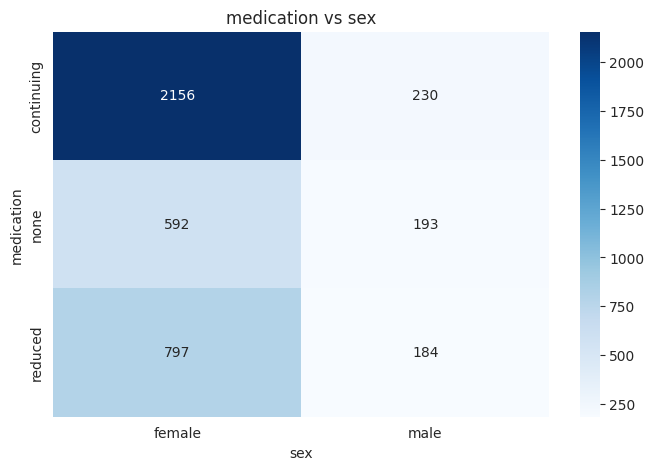


Contingency Table: headache vs sex


sex,female,male
headache,,
no,1266,220
yes,2279,387


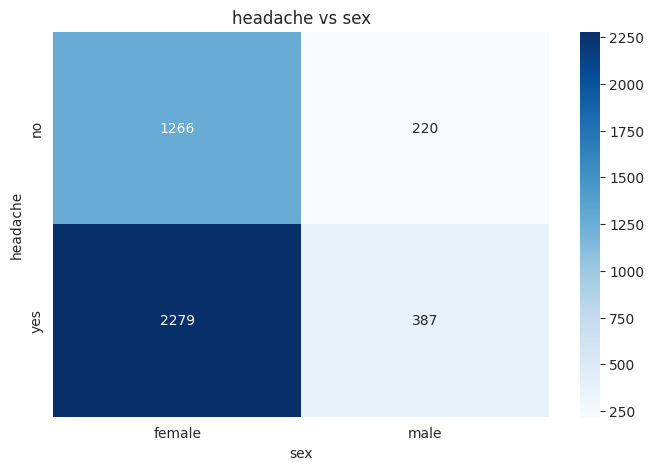

In [36]:
# 2D Statistical Analysis - Categorical vs Categorical

for i in range(len(categorical_columns)):

    for j in range(i + 1, len(categorical_columns)):

        col1 = categorical_columns[i]
        col2 = categorical_columns[j]

        print(f"\nContingency Table: {col1} vs {col2}")

        table = pd.crosstab(
            df[col1],
            df[col2]
        )

        display(table)

        plt.figure(figsize=(8, 5))

        sns.heatmap(
            table,
            annot=True,
            fmt='d',
            cmap='Blues'
        )

        plt.title(f"{col1} vs {col2}")

        plt.show()

In [37]:
# 2D Statistical Analysis - Chi-Square Test

from scipy.stats import chi2_contingency

for i in range(len(categorical_columns)):

    for j in range(i + 1, len(categorical_columns)):

        col1 = categorical_columns[i]
        col2 = categorical_columns[j]

        table = pd.crosstab(
            df[col1],
            df[col2]
        )

        chi2, p, dof, expected = chi2_contingency(table)

        print(f"\nChi-Square Test: {col1} vs {col2}")
        print("Chi-square statistic:", chi2)
        print("p-value:", p)
        print("Degrees of freedom:", dof)

        if p < 0.05:
            print("Result: Statistically significant association")
        else:
            print("Result: No statistically significant association")


Chi-Square Test: hatype vs medication
Chi-square statistic: 119.59177947992337
p-value: 6.529039020102319e-25
Degrees of freedom: 4
Result: Statistically significant association

Chi-Square Test: hatype vs headache
Chi-square statistic: 67.20681271927494
p-value: 2.5481561909783057e-15
Degrees of freedom: 2
Result: Statistically significant association

Chi-Square Test: hatype vs sex
Chi-square statistic: 259.94962922327386
p-value: 3.569893234435195e-57
Degrees of freedom: 2
Result: Statistically significant association

Chi-Square Test: medication vs headache
Chi-square statistic: 216.8327324055683
p-value: 8.229442405453777e-48
Degrees of freedom: 2
Result: Statistically significant association

Chi-Square Test: medication vs sex
Chi-square statistic: 123.3242709570225
p-value: 1.6614023457408622e-27
Degrees of freedom: 2
Result: Statistically significant association

Chi-Square Test: headache vs sex
Chi-square statistic: 0.042688484136431136
p-value: 0.8363129528687885
Degrees of 

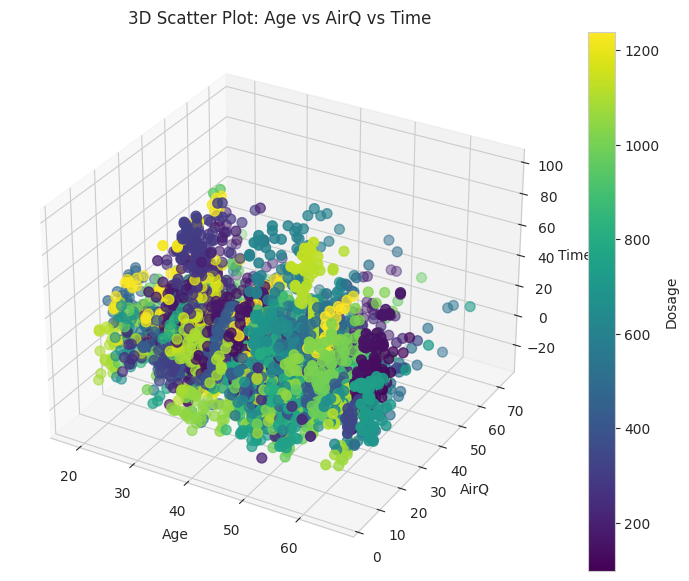

In [38]:
# 3D Statistical Analysis - 3D Scatter Plot

from mpl_toolkits.mplot3d import Axes3D

x = df['age']
y = df['airq']
z = df['time']

fig = plt.figure(figsize=(10, 7))

ax = fig.add_subplot(
    111,
    projection='3d'
)

scatter = ax.scatter(
    x,
    y,
    z,
    c=df['dos'],
    cmap='viridis',
    s=50
)

ax.set_xlabel("Age")
ax.set_ylabel("AirQ")
ax.set_zlabel("Time")

ax.set_title(
    "3D Scatter Plot: Age vs AirQ vs Time"
)

plt.colorbar(
    scatter,
    label="Dosage"
)

plt.show()

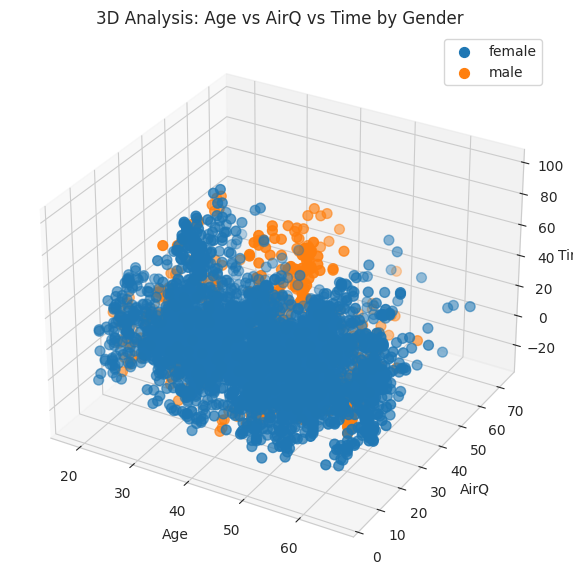

In [39]:
# 3D Statistical Analysis - Grouped by Gender

fig = plt.figure(figsize=(10, 7))

ax = fig.add_subplot(
    111,
    projection='3d'
)

for gender in df['sex'].unique():

    subset = df[df['sex'] == gender]

    ax.scatter(
        subset['age'],
        subset['airq'],
        subset['time'],
        label=str(gender),
        s=50
    )

ax.set_xlabel("Age")
ax.set_ylabel("AirQ")
ax.set_zlabel("Time")

ax.set_title(
    "3D Analysis: Age vs AirQ vs Time by Gender"
)

ax.legend()

plt.show()

In [40]:
# K-Means Clustering - Data Preparation

from sklearn.preprocessing import StandardScaler

cluster_data = df[numeric_columns].copy()

cluster_data = cluster_data.dropna()

scaler = StandardScaler()

scaled_data = scaler.fit_transform(
    cluster_data
)

print("Original Shape:", cluster_data.shape)
print("Scaled Shape:", scaled_data.shape)

Original Shape: (4152, 6)
Scaled Shape: (4152, 6)


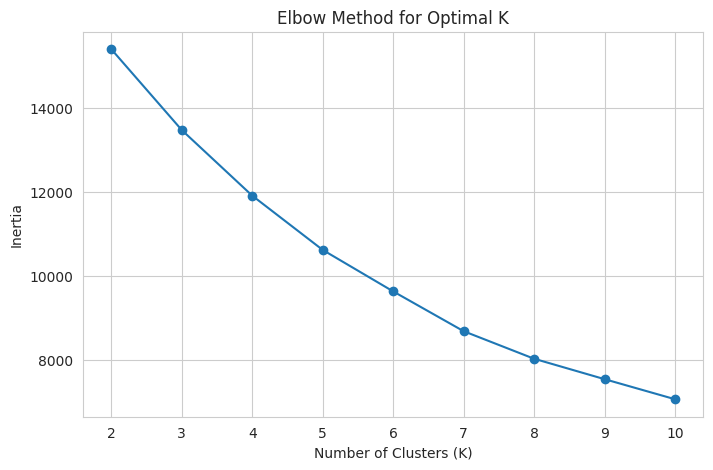

In [41]:
# K-Means Clustering - Elbow Method

from sklearn.cluster import KMeans

inertia = []

K = range(2, 11)

for k in K:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(scaled_data)

    inertia.append(
        kmeans.inertia_
    )

plt.figure(figsize=(8, 5))

plt.plot(
    K,
    inertia,
    marker='o'
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")

plt.title(
    "Elbow Method for Optimal K"
)

plt.show()

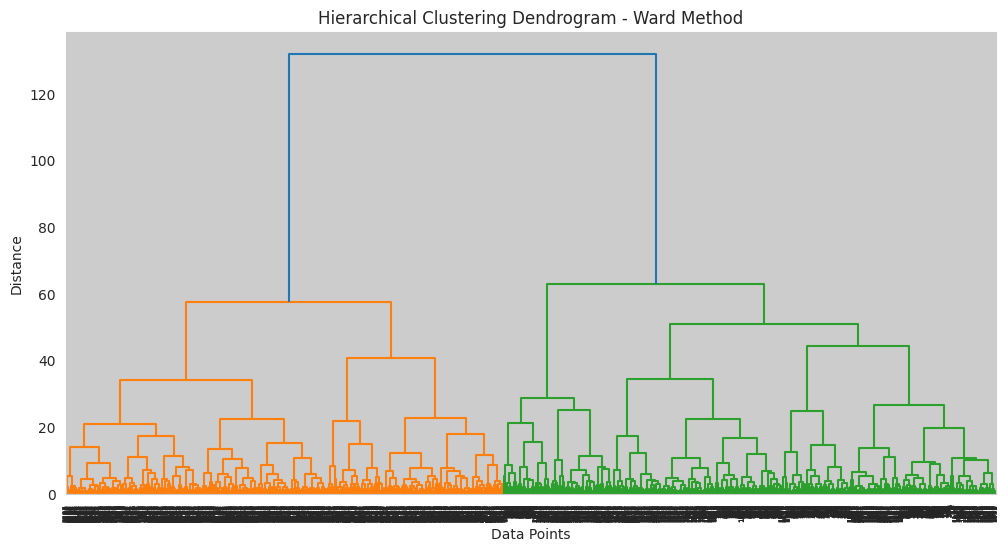

In [42]:
# Hierarchical Clustering - Ward Method

from scipy.cluster.hierarchy import (
    dendrogram,
    linkage
)

linked_ward = linkage(
    scaled_data,
    method='ward'
)

plt.figure(figsize=(12, 6))

dendrogram(
    linked_ward
)

plt.title(
    "Hierarchical Clustering Dendrogram - Ward Method"
)

plt.xlabel("Data Points")
plt.ylabel("Distance")

plt.show()

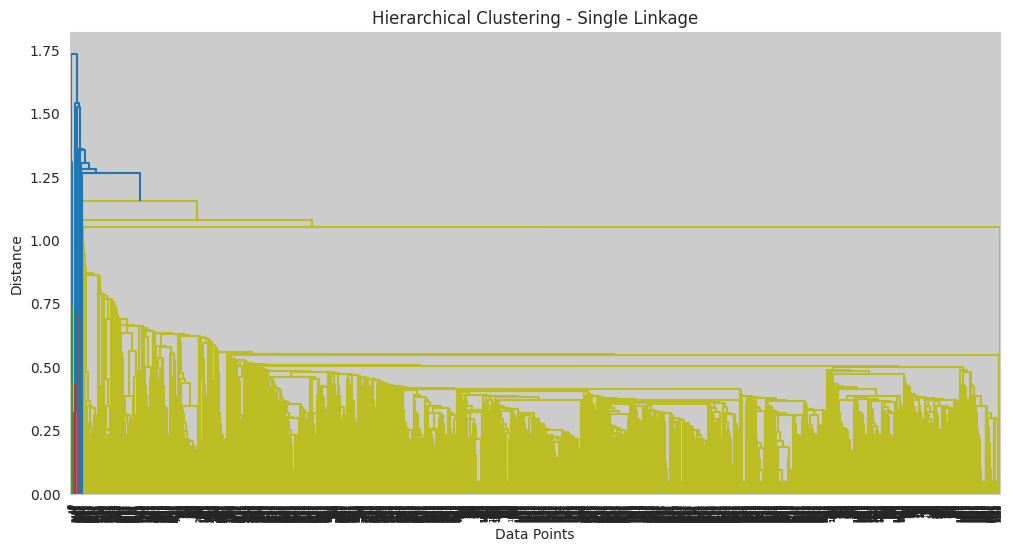

In [43]:
# Hierarchical Clustering - Single Linkage

linked_single = linkage(
    scaled_data,
    method='single'
)

plt.figure(figsize=(12, 6))

dendrogram(
    linked_single
)

plt.title(
    "Hierarchical Clustering - Single Linkage"
)

plt.xlabel("Data Points")
plt.ylabel("Distance")

plt.show()

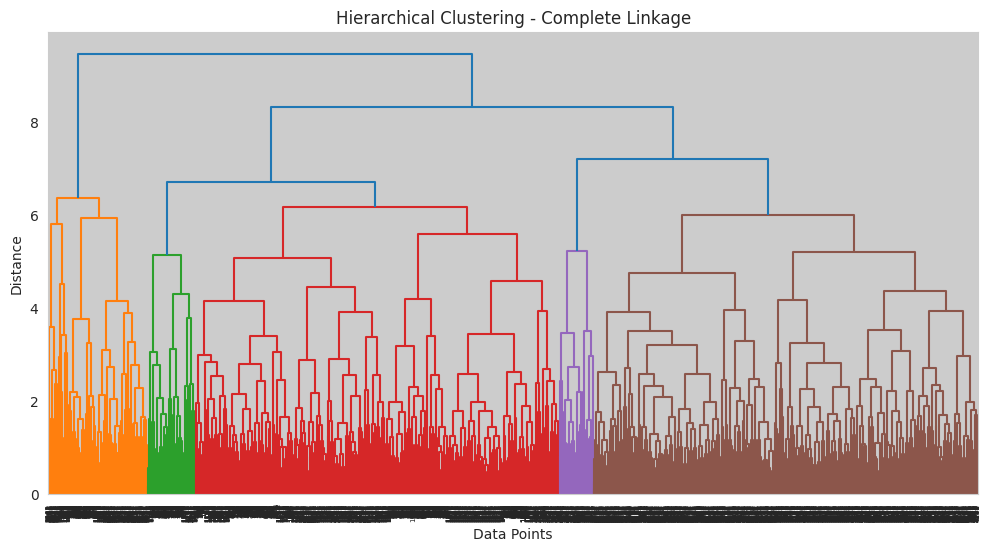

In [44]:
# Hierarchical Clustering - Complete Linkage

linked_complete = linkage(
    scaled_data,
    method='complete'
)

plt.figure(figsize=(12, 6))

dendrogram(
    linked_complete
)

plt.title(
    "Hierarchical Clustering - Complete Linkage"
)

plt.xlabel("Data Points")
plt.ylabel("Distance")

plt.show()

Explained Variance Ratio:
[5.00754867e-01 1.73663601e-01 1.64212368e-01 1.55416859e-01
 5.85643477e-03 9.58702615e-05]

Cumulative Explained Variance:
[0.50075487 0.67441847 0.83863084 0.99404769 0.99990413 1.        ]


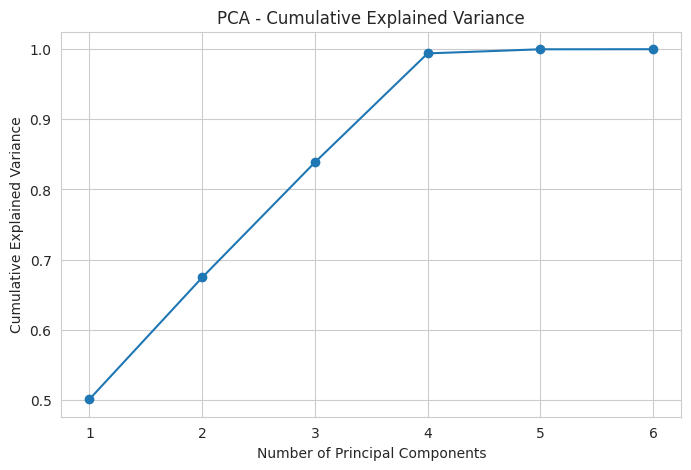

In [46]:
# PCA - Principal Component Analysis

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Select numerical features
pca_data = df.select_dtypes(include=np.number).dropna()

# Standardize the data
pca_scaler = StandardScaler()
pca_scaled = pca_scaler.fit_transform(pca_data)

# Apply PCA
pca = PCA()
pca_result = pca.fit_transform(pca_scaled)

# Explained variance
explained_variance = pca.explained_variance_ratio_

print("Explained Variance Ratio:")
print(explained_variance)

print("\nCumulative Explained Variance:")
print(np.cumsum(explained_variance))

# Plot explained variance
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(explained_variance) + 1),
    np.cumsum(explained_variance),
    marker='o'
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA - Cumulative Explained Variance")
plt.grid(True)
plt.show()

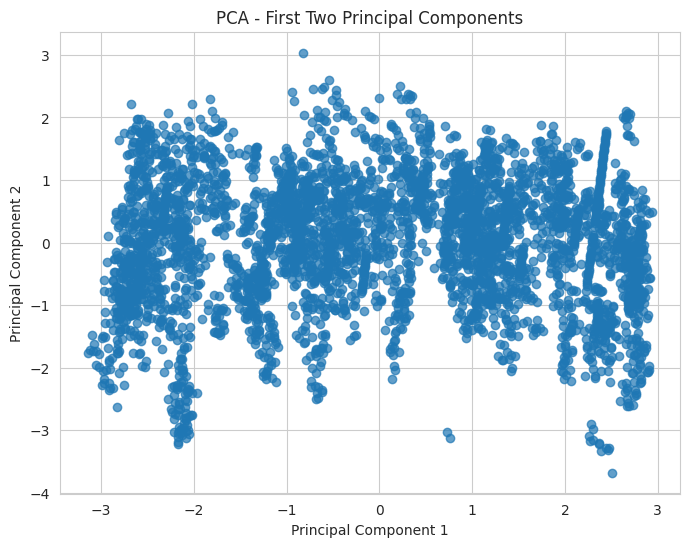

In [47]:
# Visualize the first two principal components

plt.figure(figsize=(8, 6))

plt.scatter(
    pca_result[:, 0],
    pca_result[:, 1],
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA - First Two Principal Components")
plt.grid(True)
plt.show()

Simple Linear Regression Results
Intercept: 24.682761810716503
Coefficient: 0.003361166505383659
MAE: 7.082001419180267
MSE: 87.50166863490489
R2 Score: -0.0005202299441549041


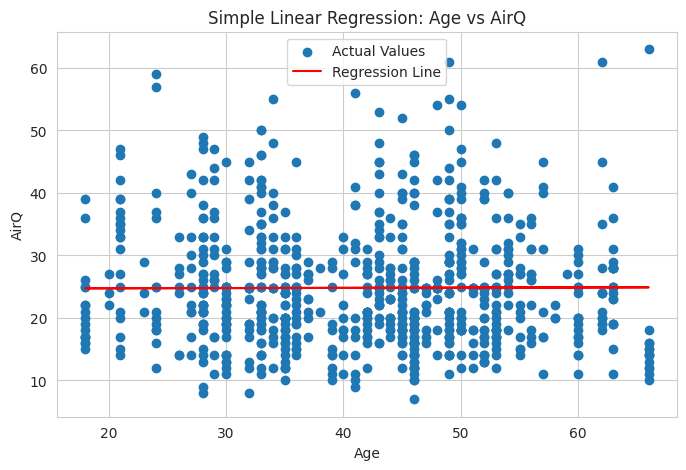

In [48]:
# Simple Linear Regression

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Select independent and dependent variables
slr_data = df[['age', 'airq']].dropna()

X = slr_data[['age']]
y = slr_data['airq']

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Train the model
slr_model = LinearRegression()
slr_model.fit(X_train, y_train)

# Make predictions
y_pred = slr_model.predict(X_test)

# Display model results
print("Simple Linear Regression Results")
print("Intercept:", slr_model.intercept_)
print("Coefficient:", slr_model.coef_[0])
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

# Plot regression line
plt.figure(figsize=(8, 5))

plt.scatter(X_test['age'], y_test, label="Actual Values")
plt.plot(
    X_test['age'],
    y_pred,
    color='red',
    label="Regression Line"
)

plt.xlabel("Age")
plt.ylabel("AirQ")
plt.title("Simple Linear Regression: Age vs AirQ")
plt.legend()
plt.show()

Logistic Regression Results
Accuracy: 0.7015643802647413

Classification Report:
              precision    recall  f1-score   support

          no       0.67      0.32      0.43       297
         yes       0.71      0.91      0.80       534

    accuracy                           0.70       831
   macro avg       0.69      0.62      0.62       831
weighted avg       0.70      0.70      0.67       831



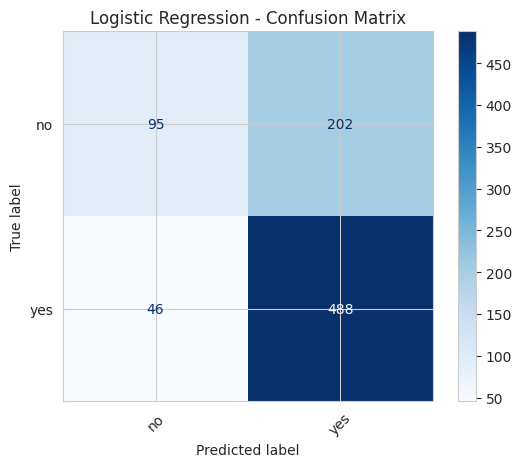

In [49]:
# Logistic Regression Classification

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Prepare the dataset
classification_data = df.dropna(subset=['headache']).copy()

X = classification_data.drop(columns=['headache'])
y = classification_data['headache'].astype(str)

# Identify numerical and categorical features
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

# Preprocess numerical and categorical columns
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

# Split data
stratify_y = y if y.value_counts().min() >= 2 else None

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=stratify_y
)

# Build and train the model
logistic_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

logistic_model.fit(X_train, y_train)

# Predictions
y_pred = logistic_model.predict(X_test)

print("Logistic Regression Results")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap='Blues',
    xticks_rotation=45
)

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

Decision Tree Classification Results
Accuracy: 0.703971119133574

Classification Report:
              precision    recall  f1-score   support

          no       0.73      0.28      0.40       297
         yes       0.70      0.94      0.80       534

    accuracy                           0.70       831
   macro avg       0.71      0.61      0.60       831
weighted avg       0.71      0.70      0.66       831



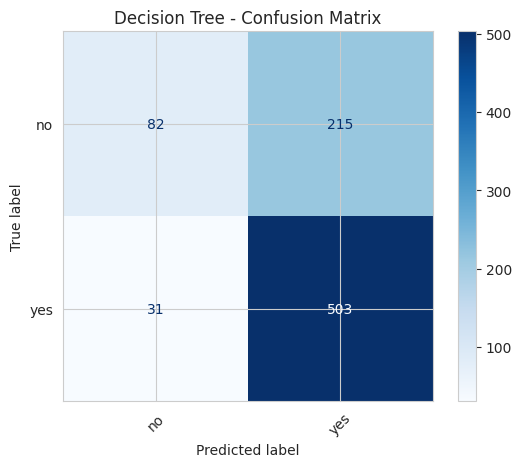

In [50]:
# Decision Tree Classification

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import ConfusionMatrixDisplay

# Train the Decision Tree using the same training and test sets
decision_tree_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(
        max_depth=4,
        random_state=42
    ))
])

decision_tree_model.fit(X_train, y_train)

# Predictions
tree_pred = decision_tree_model.predict(X_test)

print("Decision Tree Classification Results")
print("Accuracy:", accuracy_score(y_test, tree_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    tree_pred,
    zero_division=0
))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    tree_pred,
    cmap='Blues',
    xticks_rotation=45
)

plt.title("Decision Tree - Confusion Matrix")
plt.show()

                 Model  Accuracy
0  Logistic Regression  0.701564
1        Decision Tree  0.703971


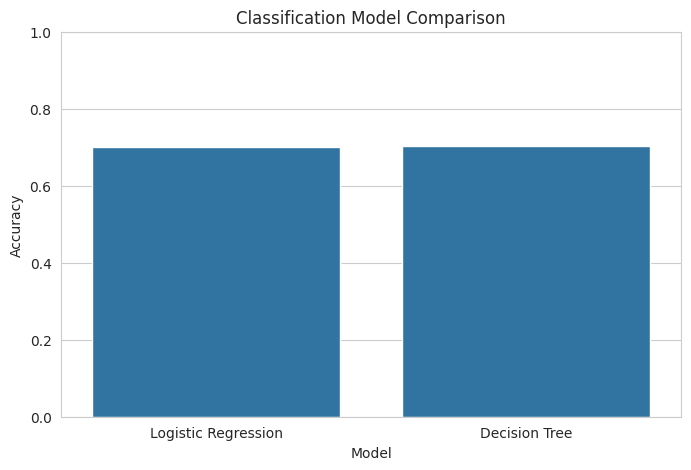

In [51]:
# Compare classification model accuracy

from sklearn.metrics import accuracy_score

results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree'
    ],
    'Accuracy': [
        accuracy_score(y_test, logistic_model.predict(X_test)),
        accuracy_score(y_test, decision_tree_model.predict(X_test))
    ]
})

print(results)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=results,
    x='Model',
    y='Accuracy'
)

plt.title("Classification Model Comparison")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.show()

In [52]:
# Final Conclusion

print("FINAL EDA AND MACHINE LEARNING CONCLUSION")

print("""
1. The dataset was loaded and inspected successfully.

2. Data preprocessing included checking missing values,
   duplicate records, data types, and categorical variables.

3. 1D statistical analysis was performed using:
   Mean, Median, Mode, Variance, Standard Deviation,
   Range, Skewness, Kurtosis, Histograms, Box Plots,
   and Frequency Distributions.

4. 2D statistical analysis included:
   Covariance, Correlation, Scatter Plots, Pair Plots,
   Categorical vs Numerical Analysis,
   Categorical vs Categorical Analysis,
   and Chi-Square Tests.

5. 3D statistical analysis was performed using
   three-dimensional scatter plots involving Age,
   AirQ and Time.

6. K-Means clustering was performed after
   standardizing the numerical variables.
   The Elbow Method and Silhouette Score were
   used to determine the number of clusters.

7. Hierarchical clustering was performed using:
   Single Linkage, Complete Linkage and Ward Linkage.

8. Dendrograms were generated to visualize the
   hierarchical relationships among observations.

9. K-Means and Hierarchical Clustering were compared
   using the Silhouette Score.

10. Principal Component Analysis (PCA) was performed
    on standardized numerical features to reduce
    dimensionality and analyze explained variance.

11. Simple Linear Regression (SLR) was implemented
    to predict AirQ using Age as the independent variable.
    Model performance was evaluated using MAE, MSE
    and R-squared score.

12. Logistic Regression classification was performed
    to predict headache outcomes using available features.
    Performance was evaluated using accuracy,
    precision, recall, F1-score and a confusion matrix.

13. Decision Tree classification was implemented
    as an additional supervised learning method.
    Its performance was evaluated using classification
    metrics and a confusion matrix.

14. Logistic Regression and Decision Tree models
    were compared using their classification accuracy.

15. Overall, the analysis covered data preprocessing,
    exploratory data analysis, statistical analysis,
    dimensionality reduction, clustering, regression
    and classification techniques.
""")

FINAL EDA AND MACHINE LEARNING CONCLUSION

1. The dataset was loaded and inspected successfully.

2. Data preprocessing included checking missing values,
   duplicate records, data types, and categorical variables.

3. 1D statistical analysis was performed using:
   Mean, Median, Mode, Variance, Standard Deviation,
   Range, Skewness, Kurtosis, Histograms, Box Plots,
   and Frequency Distributions.

4. 2D statistical analysis included:
   Covariance, Correlation, Scatter Plots, Pair Plots,
   Categorical vs Numerical Analysis,
   Categorical vs Categorical Analysis,
   and Chi-Square Tests.

5. 3D statistical analysis was performed using
   three-dimensional scatter plots involving Age,
   AirQ and Time.

6. K-Means clustering was performed after
   standardizing the numerical variables.
   The Elbow Method and Silhouette Score were
   used to determine the number of clusters.

7. Hierarchical clustering was performed using:
   Single Linkage, Complete Linkage and Ward Linkage.

8. Den